# Algorithm Implementation and Experimental Evaluation

## 1. Introduction
- **Implementation purpose**: Implement and experimentally evaluate 4 modern cryptographic components from first principles, strictly without using any existing cryptographic library (such as `cryptography`, `PyCryptodome`, `hashlib`, `hmac`).
- **Student information**:
  - Full name: **Nguyen Thi Khanh Linh**
  - Student ID (SID): `064306000108` (last digit: `8`)
- **Topic assignment by SID**:
  - Symmetric cryptography: **AES-128 (CBC mode + PKCS#7 padding)**, key derived from the first 128 bits of SHA-256(student's full name in UTF-8).
  - Asymmetric cryptography: $\text{SID} \pmod 3 = 8 \pmod 3 = 2 \implies$ **Elliptic Curve secp256k1 & ECDH Key Exchange**.
  - Cryptographic hash function: **SHA-256 (FIPS 180-4)**.
  - Digital Signature: $\text{SID} \pmod 4 = 8 \pmod 4 = 0 \implies$ **ElGamal Digital Signature (RFC 3526 Group 14 - 2048-bit)**.

### Input / Output specification of the algorithms:

| Algorithm | Implementation purpose | Input data | Output data |
|---|---|---|---|
| **SHA-256** | One-way cryptographic hash function | `bytes` string of arbitrary length | 32-byte (256-bit) digest |
| **AES-128 CBC** | Symmetric encryption for data confidentiality | Plaintext `bytes`, 16-byte key, 16-byte IV | `ciphertext` (a multiple of 16 bytes) |
| **ECC secp256k1 & ECDH** | Asymmetric key exchange | Private key $d$, peer's public key $Q$ | Shared secret point $S = d \cdot Q$ |
| **ElGamal Digital Signature** | Integrity and origin authentication | Message $m$, private key $x$, parameters $(p, g)$ | Digital signature pair $(r, s)$ |


In [1]:
# Initialize the runtime environment, declare the configuration and define the Markdown table display utility
import sys
import os
import time
import platform
import secrets
from dataclasses import dataclass
from pathlib import Path
from typing import Tuple, List, Optional
import IPython
from IPython.display import Markdown, display

# Set up the project root directory
PROJECT_ROOT = Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
src_path = str(PROJECT_ROOT / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

# Student information and topic assignment
STUDENT_NAME = "Nguyen Thi Khanh Linh"
STUDENT_ID = "064306000108"
LAST_DIGIT = int(STUDENT_ID[-1])
ASYMMETRIC_ALLOC = LAST_DIGIT % 3  # 8 mod 3 = 2 -> ECC
SIGNATURE_ALLOC = LAST_DIGIT % 4   # 8 mod 4 = 0 -> ElGamal

def show_table(headers: List[str], rows: List[List[object]], title: Optional[str] = None, column_align: Optional[dict] = None):
    """Display tabular data as a standard Markdown table."""
    align_marks = {"left": "---", "center": ":---:", "right": "---:"}

    def esc(cell: object) -> str:
        return str(cell).replace("|", "\\|").replace("\n", " ")

    lines = []
    if title:
        lines.append(f"#### {title}")
        lines.append("")
    lines.append("| " + " | ".join(esc(h) for h in headers) + " |")
    lines.append("|" + "|".join(align_marks[(column_align or {}).get(i, "left")] for i in range(len(headers))) + "|")
    for row in rows:
        lines.append("| " + " | ".join(esc(c) for c in row) + " |")
    display(Markdown("\n".join(lines)))

# Display the student profile and topic assignment table
profile_headers = ["Item", "Student information / Technical specification", "Assignment rule & Theoretical basis"]
profile_rows = [
    ["Student full name", f"**{STUDENT_NAME}**", "Identity of the student carrying out the project"],
    ["Student ID (SID)", f"`{STUDENT_ID}`", f"Last digit = {LAST_DIGIT}"],
    ["Symmetric algorithm", "**AES-128 (CBC mode + PKCS#7 padding)**", "Key K = first 16 bytes of SHA-256(UTF-8 Name)"],
    ["Asymmetric algorithm", "**ECC secp256k1 & ECDH Key Exchange**", f"SID mod 3 = {LAST_DIGIT} mod 3 = {ASYMMETRIC_ALLOC} -> ECC topic"],
    ["Cryptographic hash function", "**SHA-256 (FIPS 180-4)**", "FIPS 180-4 standard, message hashing & key derivation"],
    ["Digital signature", "**ElGamal (RFC 3526 Group 14 - 2048 bit)**", f"SID mod 4 = {LAST_DIGIT} mod 4 = {SIGNATURE_ALLOC} -> ElGamal topic"],
    ["Implementation principle", "**100% First-Principles (Standard pure Python)**", "Absolutely no existing cryptographic libraries"]
]
show_table(profile_headers, profile_rows, title="STUDENT PROFILE AND CRYPTOGRAPHY TOPIC ASSIGNMENT")

#### STUDENT PROFILE AND CRYPTOGRAPHY TOPIC ASSIGNMENT

| Item | Student information / Technical specification | Assignment rule & Theoretical basis |
|---|---|---|
| Student full name | **Nguyen Thi Khanh Linh** | Identity of the student carrying out the project |
| Student ID (SID) | `064306000108` | Last digit = 8 |
| Symmetric algorithm | **AES-128 (CBC mode + PKCS#7 padding)** | Key K = first 16 bytes of SHA-256(UTF-8 Name) |
| Asymmetric algorithm | **ECC secp256k1 & ECDH Key Exchange** | SID mod 3 = 8 mod 3 = 2 -> ECC topic |
| Cryptographic hash function | **SHA-256 (FIPS 180-4)** | FIPS 180-4 standard, message hashing & key derivation |
| Digital signature | **ElGamal (RFC 3526 Group 14 - 2048 bit)** | SID mod 4 = 8 mod 4 = 0 -> ElGamal topic |
| Implementation principle | **100% First-Principles (Standard pure Python)** | Absolutely no existing cryptographic libraries |

## 2. Algorithm Components
- **List of algorithm components**: The project is modularized into 5 independent source files in the `src/crypto_lab/` directory.
- **Role and function of each component**:

| Module | Main components | Role and technical function |
|---|---|---|
| `utils.py` | Basic utility functions | Integer/bytes conversion (Big-Endian), 32-bit bit rotation (`rotr32`, `rotl32`), byte XOR (`xor_bytes`), extended Euclidean algorithm (`gcd`, `mod_inverse`). |
| `sha256.py` | SHA-256 hash function | Data padding (`pad_message`), 64 round constants $K_t$, 64-round compression function (`sha256_compress`), 256-bit digest computation (`sha256_bytes`, `sha256_hex`). |
| `aes128.py` | AES-128 block cipher | Finite field arithmetic $GF(2^8)$, S-box/InvS-box generation via the Affine transformation, expansion into 11 round keys (`key_expansion`), SubBytes, ShiftRows, MixColumns and AddRoundKey transformations, CBC mode and PKCS#7 padding. |
| `ecc.py` | Elliptic curve | Point class `Point` (Affine), on-curve point check (`is_on_curve`), point addition, point doubling, Double-and-Add scalar multiplication (`scalar_mul`), keypair generation via rejection sampling (`generate_keypair`), and ECDH key exchange (`ecdh_shared_secret`). |
| `elgamal.py` | ElGamal Digital Signature | 2048-bit safe prime MODP Group 14 (RFC 3526), keypair generation (`generate_keypair`), signing (`elgamal_sign`), signature verification (`elgamal_verify`), and private key recovery when nonce $k$ is reused. |

- **Relationships between components (Data Flow & Architecture)**:
  - `utils.py` acts as the foundation layer: it provides bit rotation for `sha256.py`, XOR for `aes128.py`, and modular inverse for `ecc.py` and `elgamal.py`.
  - `sha256.py` acts as the hashing bridge: it hashes the student's full name to derive the 128-bit key for `aes128.py`; it hashes the shared secret point $S.x$ from `ecc.py` to produce the session key; and it hashes the message before it enters the signing scheme of `elgamal.py`.
  - `ecc.py` and `aes128.py` work together: ECDH establishes the secure session key, and AES-128 CBC uses that session key to encrypt the transmission channel.
  - `elgamal.py` guarantees integrity and non-repudiation of the data before it is encrypted or transmitted.


In [2]:
# Check the integrity and collect statistics of the source code modules in the project
module_files = [
    ("src/crypto_lab/utils.py", "Arithmetic & Bit Processing", "int_to_bytes, bytes_to_int, rotr32, rotl32, xor_bytes, gcd, mod_inverse"),
    ("src/crypto_lab/sha256.py", "SHA-256 Hash Function", "pad_message, _compress, sha256, sha256_bytes, sha256_hex"),
    ("src/crypto_lab/aes128.py", "AES-128 Symmetric Encryption", "key_expansion, aes_encrypt_block, aes_encrypt_cbc, aes_decrypt_cbc, pkcs7_pad"),
    ("src/crypto_lab/ecc.py", "secp256k1 Curve & ECDH", "Point, is_on_curve, point_add, point_double, scalar_mul, generate_keypair, ecdh_shared_secret, derive_session_key"),
    ("src/crypto_lab/elgamal.py", "ElGamal 2048-bit Digital Signature", "generate_keypair, elgamal_sign, elgamal_verify, recover_private_key_reused_nonce"),
]

mod_headers = ["No.", "Source module", "Component category", "Main function set", "Size", "Status"]
mod_rows = []
for idx, (rel_path, comp_type, funcs) in enumerate(module_files, start=1):
    file_path = PROJECT_ROOT / rel_path
    exists = file_path.exists()
    size = f"{file_path.stat().st_size:,} bytes" if exists else "N/A"
    status = "PASSED" if exists else "MISSING"
    mod_rows.append([idx, f"`{rel_path}`", comp_type, f"`{funcs}`", size, status])

show_table(mod_headers, mod_rows, title="SOURCE CODE MODULE INTEGRITY CHECK TABLE")

#### SOURCE CODE MODULE INTEGRITY CHECK TABLE

| No. | Source module | Component category | Main function set | Size | Status |
|---|---|---|---|---|---|
| 1 | `src/crypto_lab/utils.py` | Arithmetic & Bit Processing | `int_to_bytes, bytes_to_int, rotr32, rotl32, xor_bytes, gcd, mod_inverse` | 1,857 bytes | PASSED |
| 2 | `src/crypto_lab/sha256.py` | SHA-256 Hash Function | `pad_message, _compress, sha256, sha256_bytes, sha256_hex` | 5,675 bytes | PASSED |
| 3 | `src/crypto_lab/aes128.py` | AES-128 Symmetric Encryption | `key_expansion, aes_encrypt_block, aes_encrypt_cbc, aes_decrypt_cbc, pkcs7_pad` | 9,537 bytes | PASSED |
| 4 | `src/crypto_lab/ecc.py` | secp256k1 Curve & ECDH | `Point, is_on_curve, point_add, point_double, scalar_mul, generate_keypair, ecdh_shared_secret, derive_session_key` | 6,453 bytes | PASSED |
| 5 | `src/crypto_lab/elgamal.py` | ElGamal 2048-bit Digital Signature | `generate_keypair, elgamal_sign, elgamal_verify, recover_private_key_reused_nonce` | 5,627 bytes | PASSED |

## 3. Python Implementation
Below is the detailed source code of all functions implemented from first principles, arranged sequentially by functional group, together with execution examples and I/O checks.


### 3.1 Group of Arithmetic and Bit/Byte Processing Utility Functions (`src/crypto_lab/utils.py`)

#### 3.1.1 Conversion between integers and bytes (`int_to_bytes`, `bytes_to_int`)
- **Function**: Convert back and forth between large integers and bytes strings in Big-Endian order.
- **Input**: Integer `n: int`, length `length: int` / String `b: bytes`.
- **Output**: The corresponding `bytes` string / The corresponding `int` integer.


In [3]:
def int_to_bytes(n: int, length: int, byteorder: str = "big") -> bytes:
    """Convert an integer to a bytes string."""
    return n.to_bytes(length, byteorder=byteorder)


def bytes_to_int(b: bytes, byteorder: str = "big") -> int:
    """Convert a bytes string to an integer."""
    return int.from_bytes(b, byteorder=byteorder)


# Execution check:
val = 0x0123456789ABCDEF
b_data = int_to_bytes(val, 8, "big")
recovered_val = bytes_to_int(b_data, "big")

print(f"Input Integer : 0x{val:016X}")
print(f"Output Bytes  : {b_data.hex()}")
print(f"Recovered Int : 0x{recovered_val:016X}")
print(f"Match check   : {recovered_val == val}")


Input Integer : 0x0123456789ABCDEF
Output Bytes  : 0123456789abcdef
Recovered Int : 0x0123456789ABCDEF
Match check   : True


#### 3.1.2 32-bit bit rotation (`rotr32`, `rotl32`)
- **Function**: Rotate right (ROTR) and rotate left (ROTL) by $n$ bits on a 32-bit integer: $\text{ROTR}^n(x) = (x \gg n) \mid (x \ll (32 - n))$.
- **Input**: 32-bit value `x: int`, number of rotation positions `n: int`.
- **Output**: The 32-bit value after rotation.


In [4]:
def rotr32(x: int, n: int) -> int:
    """Rotate right by n bits on a 32-bit integer."""
    n = n % 32
    return ((x >> n) | (x << (32 - n))) & 0xFFFFFFFF


def rotl32(x: int, n: int) -> int:
    """Rotate left by n bits on a 32-bit integer."""
    n = n % 32
    return ((x << n) | (x >> (32 - n))) & 0xFFFFFFFF


# Execution check:
x_test = 0x80000001
rotr_res = rotr32(x_test, 1)
rotl_res = rotl32(x_test, 1)

print(f"Initial value   : 0x{x_test:08X} ({x_test:032b})")
print(f"rotr32(x, 1)    : 0x{rotr_res:08X} ({rotr_res:032b})")
print(f"rotl32(x, 1)    : 0x{rotl_res:08X} ({rotl_res:032b})")


Initial value   : 0x80000001 (10000000000000000000000000000001)
rotr32(x, 1)    : 0xC0000000 (11000000000000000000000000000000)
rotl32(x, 1)    : 0x00000003 (00000000000000000000000000000011)


#### 3.1.3 Byte-wise XOR (`xor_bytes`)
- **Function**: Perform a byte-wise XOR between two bytes strings of equal length (used in AES-CBC mode).
- **Input**: Two bytes strings `a`, `b` of the same size.
- **Output**: The bytes string resulting from the XOR operation.


In [5]:
def xor_bytes(a: bytes, b: bytes) -> bytes:
    """Byte-wise XOR of two bytes strings of equal length."""
    if len(a) != len(b):
        raise ValueError(f"Both bytes strings must have equal length: {len(a)} != {len(b)}")
    return bytes(x ^ y for x, y in zip(a, b))


# Execution check:
blk_a = bytes.fromhex("00112233445566778899aabbccddeeff")
blk_b = bytes.fromhex("ffffffffffffffffffffffffffffffff")
xored = xor_bytes(blk_a, blk_b)

print(f"Block A : {blk_a.hex()}")
print(f"Block B : {blk_b.hex()}")
print(f"XOR Out : {xored.hex()}")


Block A : 00112233445566778899aabbccddeeff
Block B : ffffffffffffffffffffffffffffffff
XOR Out : ffeeddccbbaa99887766554433221100


#### 3.1.4 Greatest common divisor & Modular inverse (`gcd`, `mod_inverse`)
- **Function**: Find $\gcd(a, b)$ using the Euclidean algorithm and compute the modular inverse $a^{-1} \pmod m$ such that $(a \cdot x) \equiv 1 \pmod m$.
- **Input**: $a, m \in \mathbb{Z}$ with $m > 1$ and $\gcd(a, m) = 1$.
- **Output**: The modular inverse value $x \in [1, m - 1]$.


In [6]:
def gcd(a: int, b: int) -> int:
    '''Greatest common divisor (Euclidean algorithm).'''
    while b != 0:
        a, b = b, a % b
    return abs(a)


def extended_gcd(a: int, b: int) -> tuple[int, int, int]:
    '''Extended Euclidean algorithm: find gcd(a, b) and the Bézout coefficients x, y.'''
    x0, x1, y0, y1 = 1, 0, 0, 1
    while b != 0:
        q = a // b
        a, b = b, a % b
        x0, x1 = x1, x0 - q * x1
        y0, y1 = y1, y0 - q * y1
    return a, x0, y0


def mod_inverse(a: int, m: int) -> int:
    '''Compute the modular inverse of a modulo m using the extended Euclidean algorithm.'''
    if m <= 1:
        raise ValueError('Modulus m must be greater than 1.')
    g, x, _ = extended_gcd(a % m, m)
    if g != 1:
        raise ValueError(f'No modular inverse of {a} modulo {m} exists')
    return (x % m + m) % m


# Execution check:
a_num, m_num = 3, 26
inv_val = mod_inverse(a_num, m_num)

print(f'gcd(54, 24) = {gcd(54, 24)}')
print(f'Inverse of {a_num} mod {m_num} = {inv_val}')
print(f'Identity check: ({a_num} * {inv_val}) % {m_num} = {(a_num * inv_val) % m_num}')


gcd(54, 24) = 6
Inverse of 3 mod 26 = 9
Identity check: (3 * 9) % 26 = 1


### 3.2 SHA-256 Cryptographic Hash Function Module (`src/crypto_lab/sha256.py`)

#### 3.2.1 Initial constants and round transformation logic functions
- **Function**: Initialize the 8 initial state words $H_0..H_7$, the 64 round constants $K_t$ and the non-linear logic functions $Ch, Maj, \Sigma_0, \Sigma_1, \sigma_0, \sigma_1$ according to FIPS 180-4.
- **Input**: 32-bit words.
- **Output**: The 32-bit word after transformation.


In [7]:
INITIAL_HASH_VALUES = [
    0x6A09E667, 0xBB67AE85, 0x3C6EF372, 0xA54FF53A,
    0x510E527F, 0x9B05688C, 0x1F83D9AB, 0x5BE0CD19,
]

ROUND_CONSTANTS = [
    0x428A2F98, 0x71374491, 0xB5C0FBCF, 0xE9B5DBA5,
    0x3956C25B, 0x59F111F1, 0x923F82A4, 0xAB1C5ED5,
    0xD807AA98, 0x12835B01, 0x243185BE, 0x550C7DC3,
    0x72BE5D74, 0x80DEB1FE, 0x9BDC06A7, 0xC19BF174,
    0xE49B69C1, 0xEFBE4786, 0x0FC19DC6, 0x240CA1CC,
    0x2DE92C6F, 0x4A7484AA, 0x5CB0A9DC, 0x76F988DA,
    0x983E5152, 0xA831C66D, 0xB00327C8, 0xBF597FC7,
    0xC6E00BF3, 0xD5A79147, 0x06CA6351, 0x14292967,
    0x27B70A85, 0x2E1B2138, 0x4D2C6DFC, 0x53380D13,
    0x650A7354, 0x766A0ABB, 0x81C2C92E, 0x92722C85,
    0xA2BFE8A1, 0xA81A664B, 0xC24B8B70, 0xC76C51A3,
    0xD192E819, 0xD6990624, 0xF40E3585, 0x106AA070,
    0x19A4C116, 0x1E376C08, 0x2748774C, 0x34B0BCB5,
    0x391C0CB3, 0x4ED8AA4A, 0x5B9CCA4F, 0x682E6FF3,
    0x748F82EE, 0x78A5636F, 0x84C87814, 0x8CC70208,
    0x90BEFFFA, 0xA4506CEB, 0xBEF9A3F7, 0xC67178F2,
]


def _ch(x: int, y: int, z: int) -> int:
    """Logical function Ch(x, y, z)."""
    return (x & y) ^ (~x & z)


def _maj(x: int, y: int, z: int) -> int:
    """Logical function Maj(x, y, z)."""
    return (x & y) ^ (x & z) ^ (y & z)


def _big_sigma0(x: int) -> int:
    """Function Sigma_0(x)."""
    return rotr32(x, 2) ^ rotr32(x, 13) ^ rotr32(x, 22)


def _big_sigma1(x: int) -> int:
    """Function Sigma_1(x)."""
    return rotr32(x, 6) ^ rotr32(x, 11) ^ rotr32(x, 25)


def _small_sigma0(x: int) -> int:
    """Function sigma_0(x)."""
    return rotr32(x, 7) ^ rotr32(x, 18) ^ (x >> 3)


def _small_sigma1(x: int) -> int:
    """Function sigma_1(x)."""
    return rotr32(x, 17) ^ rotr32(x, 19) ^ (x >> 10)


# Execution check:
u, v, w = 0x12345678, 0x9ABCDEF0, 0x55AA55AA
print(f"Ch(u, v, w)  = 0x{_ch(u, v, w):08X}")
print(f"Maj(u, v, w) = 0x{_maj(u, v, w):08X}")
print(f"Sigma_0(u)   = 0x{_big_sigma0(u):08X}")
print(f"sigma_0(u)   = 0x{_small_sigma0(u):08X}")


Ch(u, v, w)  = 0x57BE57F2
Maj(u, v, w) = 0x12BC56F8
Sigma_0(u)   = 0x66146474
sigma_0(u)   = 0xE7FCE6EE


#### 3.2.2 Data padding (`pad_message`)
- **Function**: Pad the data per section 5.1.1 of FIPS 180-4: append a `1` bit (`0x80`), pad with `0x00` bytes so that the length is congruent to 56 mod 64, then append 8 bytes (64 bits) representing the original message length in Big-Endian.
- **Input**: `data: bytes`.
- **Output**: A `bytes` string whose length is divisible by 64 bytes.


In [8]:
def pad_message(data: bytes) -> bytes:
    """Pad the message data according to FIPS 180-4."""
    original_bit_length = len(data) * 8
    buffer = bytearray(data)
    
    # 1. Append bit 1 (0x80)
    buffer.append(0x80)
    
    # 2. Append 0 bits so that the length is congruent to 56 mod 64
    while len(buffer) % 64 != 56:
        buffer.append(0x00)
        
    # 3. Append the 64-bit big-endian representation of the original length
    buffer.extend(original_bit_length.to_bytes(8, byteorder="big"))
    
    return bytes(buffer)


# Execution check:
raw_msg = b"abc"
padded_msg = pad_message(raw_msg)

print(f"Original plaintext: '{raw_msg.decode()}' (len = {len(raw_msg)} bytes)")
print(f"Padded data       : len = {len(padded_msg)} bytes (divisible by 64: {len(padded_msg) % 64 == 0})")
print(f"First padding byte: 0x{padded_msg[len(raw_msg)]:02X} (expected 0x80)")
bit_length_field = int.from_bytes(padded_msg[-8:], "big")
print(f"64-bit length     : {bit_length_field} bits (expected {len(raw_msg) * 8} bits)")


Original plaintext: 'abc' (len = 3 bytes)
Padded data       : len = 64 bytes (divisible by 64: True)
First padding byte: 0x80 (expected 0x80)
64-bit length     : 24 bits (expected 24 bits)


#### 3.2.3 Compression function for one 512-bit block (`_compress` / `sha256_compress`)
- **Function**: Initialize the Message Schedule array $W_0..W_{63}$, compress the 64-byte block into the 8 state registers through 64 rounds, and apply the feed-forward addition modulo $2^{32}$.
- **Input**: Block `chunk: bytes` (64 bytes), current state `h: List[int]` (8 32-bit words).
- **Output**: New state `List[int]` (8 32-bit words).


In [9]:
import struct

def _compress(chunk: bytes, h: List[int]) -> List[int]:
    """Core SHA-256 compression function for one 512-bit (64-byte) block (FIPS 180-4)."""
    if len(chunk) != 64:
        raise ValueError("The compression block must be exactly 64 bytes.")

    # 1. Message Schedule W consisting of 64 32-bit words
    w = list(struct.unpack(">16L", chunk))
    for t in range(16, 64):
        s0 = _small_sigma0(w[t - 15])
        s1 = _small_sigma1(w[t - 2])
        w.append((w[t - 16] + s0 + w[t - 7] + s1) & 0xFFFFFFFF)

    # 2. Working variables initialized from the current state
    a, b, c, d, e, f, g, current_h = h

    # 3. 64 compression rounds
    for t in range(64):
        t1 = (current_h + _big_sigma1(e) + _ch(e, f, g) + ROUND_CONSTANTS[t] + w[t]) & 0xFFFFFFFF
        t2 = (_big_sigma0(a) + _maj(a, b, c)) & 0xFFFFFFFF
        
        current_h = g
        g = f
        f = e
        e = (d + t1) & 0xFFFFFFFF
        d = c
        c = b
        b = a
        a = (t1 + t2) & 0xFFFFFFFF

    # 4. Feed-forward addition modulo 2^32
    return [
        (h[0] + a) & 0xFFFFFFFF,
        (h[1] + b) & 0xFFFFFFFF,
        (h[2] + c) & 0xFFFFFFFF,
        (h[3] + d) & 0xFFFFFFFF,
        (h[4] + e) & 0xFFFFFFFF,
        (h[5] + f) & 0xFFFFFFFF,
        (h[6] + g) & 0xFFFFFFFF,
        (h[7] + current_h) & 0xFFFFFFFF,
    ]


def sha256_compress(h: List[int], chunk: bytes) -> List[int]:
    """Compatibility wrapper forwarding to _compress(chunk, h)."""
    return _compress(chunk, h)


# Execution check:
st_init = list(INITIAL_HASH_VALUES)
ch_sample = pad_message(b"abc")[:64]
st_next = _compress(ch_sample, st_init)

print("State before compression H_0..H_7 :", [hex(x) for x in st_init[:4]])
print("State after compressing 1 block   :", [hex(x) for x in st_next[:4]])


State before compression H_0..H_7 : ['0x6a09e667', '0xbb67ae85', '0x3c6ef372', '0xa54ff53a']
State after compressing 1 block   : ['0xba7816bf', '0x8f01cfea', '0x414140de', '0x5dae2223']


#### 3.2.4 Complete digest computation (`sha256_bytes`, `sha256_hex`)
- **Function**: Pad the data, compress each 64-byte block sequentially, and concatenate the 8 state words into a 32-byte digest or a 64-character hex string.
- **Input**: `data: bytes`.
- **Output**: 32-byte digest (`sha256_bytes`) / 64-character hex string (`sha256_hex`).


In [10]:
def sha256_bytes(data: bytes) -> bytes:
    """Compute the SHA-256 hash as 32 bytes."""
    padded = pad_message(data)
    state = list(INITIAL_HASH_VALUES)
    
    for offset in range(0, len(padded), 64):
        chunk = padded[offset : offset + 64]
        state = _compress(chunk, state)
        
    return b"".join(val.to_bytes(4, byteorder="big") for val in state)


def sha256_hex(data: bytes) -> str:
    """Compute the SHA-256 hash as a 64-character hex string."""
    return sha256_bytes(data).hex()


# Execution check:
msg_student = STUDENT_NAME.encode("utf-8")
print(f"Input Data   : '{STUDENT_NAME}'")
print(f"Digest Bytes : {sha256_bytes(msg_student)[:16].hex()}... ({len(sha256_bytes(msg_student))} bytes)")
print(f"Digest Hex   : {sha256_hex(msg_student)}")


Input Data   : 'Nguyen Thi Khanh Linh'
Digest Bytes : 5d7a3db0c1a37df54fe437bd2cfaf35e... (32 bytes)
Digest Hex   : 5d7a3db0c1a37df54fe437bd2cfaf35e28853fb0733abb68c31459a019a5f4d8


### 3.3 AES-128 Symmetric Encryption Module and CBC Mode (`src/crypto_lab/aes128.py`)

#### 3.3.1 Finite field arithmetic $GF(2^8)$ and S-box generation
- **Function**: Peasant/xtime-style polynomial multiplication modulo $m(x) = x^8 + x^4 + x^3 + x + 1$ (0x11B), computing the multiplicative inverse $b^{-1}$ and generating the S-box / Inv S-box tables via the Affine transformation.
- **Input**: Byte values $a, b \in [0, 255]$.
- **Output**: The product $a \cdot b \in GF(2^8)$, S-box lookup values.


In [11]:
RCON = [0x00, 0x01, 0x02, 0x04, 0x08, 0x10, 0x20, 0x40, 0x80, 0x1B, 0x36]


def gf_mul(a: int, b: int) -> int:
    """Multiply two elements in the finite field GF(2^8)."""
    p = 0
    for _ in range(8):
        if b & 1:
            p ^= a
        hi_bit = a & 0x80
        a = (a << 1) & 0xFF
        if hi_bit:
            a ^= 0x1B
        b >>= 1
    return p


def _gf_inv(b: int) -> int:
    """Multiplicative inverse of byte b in GF(2^8). Convention: 0^(-1) = 0."""
    if b == 0:
        return 0
    res, base, exp = 1, b, 254
    while exp > 0:
        if exp & 1:
            res = gf_mul(res, base)
        base = gf_mul(base, base)
        exp >>= 1
    return res


def _build_sboxes():
    """Generate the S-box and Inverse S-box via the Affine transformation."""
    s_box = [0] * 256
    inv_s_box = [0] * 256
    for val in range(256):
        inv = _gf_inv(val)
        res = 0
        for i in range(8):
            bit = (
                ((inv >> i) & 1)
                ^ ((inv >> ((i + 4) % 8)) & 1)
                ^ ((inv >> ((i + 5) % 8)) & 1)
                ^ ((inv >> ((i + 6) % 8)) & 1)
                ^ ((inv >> ((i + 7) % 8)) & 1)
                ^ ((0x63 >> i) & 1)
            )
            res |= bit << i
        s_box[val] = res
        inv_s_box[res] = val
    return s_box, inv_s_box


_SBOX, _INV_SBOX = _build_sboxes()


def sbox(b: int) -> int:
    """Look up the S-box value."""
    return _SBOX[b & 0xFF]


def inv_sbox(b: int) -> int:
    """Look up the Inverse S-box value."""
    return _INV_SBOX[b & 0xFF]


# Execution check:
print(f"gf_mul(0x57, 0x83) = 0x{gf_mul(0x57, 0x83):02X} (FIPS 197 section 4.2: 0xC1)")
print(f"sbox(0x53)          = 0x{sbox(0x53):02X} (FIPS 197 section 5.1.1: 0xED)")
print(f"inv_sbox(0xED)      = 0x{inv_sbox(0xED):02X} (Recovered: 0x53)")


gf_mul(0x57, 0x83) = 0xC1 (FIPS 197 section 4.2: 0xC1)
sbox(0x53)          = 0xED (FIPS 197 section 5.1.1: 0xED)
inv_sbox(0xED)      = 0x53 (Recovered: 0x53)


#### 3.3.2 AES-128 key expansion (`key_expansion`)
- **Function**: Expand the 16-byte (128-bit) master key into 11 round keys (44 32-bit words) per section 5.2 of FIPS 197.
- **Input**: Key `key: bytes` (16 bytes).
- **Output**: A list of 11 round keys `List[bytes]`, each round key consisting of 16 bytes.


In [12]:
def key_expansion(key: bytes) -> List[bytes]:
    """Expand a 128-bit key into 11 round keys."""
    if len(key) != 16:
        raise ValueError("The AES-128 key must be exactly 16 bytes (128 bits) long.")

    words = []
    for i in range(4):
        words.append([key[4 * i], key[4 * i + 1], key[4 * i + 2], key[4 * i + 3]])

    for i in range(4, 44):
        temp = list(words[i - 1])
        if i % 4 == 0:
            temp = temp[1:] + temp[:1]
            temp = [_SBOX[x] for x in temp]
            temp[0] ^= RCON[i // 4]
        word = [words[i - 4][j] ^ temp[j] for j in range(4)]
        words.append(word)

    round_keys = []
    for r in range(11):
        rk = []
        for c in range(4):
            rk.extend(words[r * 4 + c])
        round_keys.append(bytes(rk))

    return round_keys


# Execution check:
sample_key = bytes.fromhex("2b7e151628aed2a6abf7158809cf4f3c")
round_keys = key_expansion(sample_key)

print(f"Number of round keys : {len(round_keys)} (Expected: 11)")
print(f"Round Key 0 (Initial): {round_keys[0].hex()}")
print(f"Round Key 1          : {round_keys[1].hex()} (FIPS 197: a0fafe...)")
print(f"Round Key 10 (Final) : {round_keys[10].hex()}")


Number of round keys : 11 (Expected: 11)
Round Key 0 (Initial): 2b7e151628aed2a6abf7158809cf4f3c
Round Key 1          : a0fafe1788542cb123a339392a6c7605 (FIPS 197: a0fafe...)
Round Key 10 (Final) : d014f9a8c9ee2589e13f0cc8b6630ca6


#### 3.3.3 State matrix transformations and basic block encryption/decryption
- **Function**: Implement SubBytes, ShiftRows, MixColumns, AddRoundKey and their corresponding inverse functions. Encrypt and decrypt a 16-byte block in column-major order through 10 rounds.
- **Input**: Data block `block: bytes` (16 bytes), key `key: bytes` (16 bytes).
- **Output**: The 16-byte encrypted/decrypted block.


In [13]:
def _sub_bytes(state: List[List[int]]) -> None:
    """Substitute the bytes of the state matrix using the S-box."""
    for r in range(4):
        for c in range(4):
            state[r][c] = _SBOX[state[r][c]]


def _inv_sub_bytes(state: List[List[int]]) -> None:
    """Substitute the bytes of the state matrix using the Inverse S-box."""
    for r in range(4):
        for c in range(4):
            state[r][c] = _INV_SBOX[state[r][c]]


def _shift_rows(state: List[List[int]]) -> None:
    """Cyclically shift the rows to the left."""
    state[1] = state[1][1:] + state[1][:1]
    state[2] = state[2][2:] + state[2][:2]
    state[3] = state[3][3:] + state[3][:3]


def _inv_shift_rows(state: List[List[int]]) -> None:
    """Cyclically shift the rows to the right."""
    state[1] = state[1][-1:] + state[1][:-1]
    state[2] = state[2][-2:] + state[2][:-2]
    state[3] = state[3][-3:] + state[3][:-3]


def _mix_columns(state: List[List[int]]) -> None:
    """MixColumns column mixing over GF(2^8)."""
    for c in range(4):
        s0, s1, s2, s3 = state[0][c], state[1][c], state[2][c], state[3][c]
        state[0][c] = gf_mul(2, s0) ^ gf_mul(3, s1) ^ s2 ^ s3
        state[1][c] = s0 ^ gf_mul(2, s1) ^ gf_mul(3, s2) ^ s3
        state[2][c] = s0 ^ s1 ^ gf_mul(2, s2) ^ gf_mul(3, s3)
        state[3][c] = gf_mul(3, s0) ^ s1 ^ s2 ^ gf_mul(2, s3)


def _inv_mix_columns(state: List[List[int]]) -> None:
    """InvMixColumns, the inverse of the column mixing."""
    for c in range(4):
        s0, s1, s2, s3 = state[0][c], state[1][c], state[2][c], state[3][c]
        state[0][c] = gf_mul(0x0E, s0) ^ gf_mul(0x0B, s1) ^ gf_mul(0x0D, s2) ^ gf_mul(0x09, s3)
        state[1][c] = gf_mul(0x09, s0) ^ gf_mul(0x0E, s1) ^ gf_mul(0x0B, s2) ^ gf_mul(0x0D, s3)
        state[2][c] = gf_mul(0x0D, s0) ^ gf_mul(0x09, s1) ^ gf_mul(0x0E, s2) ^ gf_mul(0x0B, s3)
        state[3][c] = gf_mul(0x0B, s0) ^ gf_mul(0x0D, s1) ^ gf_mul(0x09, s2) ^ gf_mul(0x0E, s3)


def _add_round_key(state: List[List[int]], round_key: bytes) -> None:
    """Add the round key to the state matrix."""
    for c in range(4):
        for r in range(4):
            state[r][c] ^= round_key[c * 4 + r]


def aes_encrypt_block(block: bytes, key: bytes, round_keys: Optional[List[bytes]] = None) -> bytes:
    """Encrypt one 16-byte block with AES-128."""
    if len(block) != 16:
        raise ValueError("The AES data block must be exactly 16 bytes.")
    if round_keys is None:
        if len(key) != 16:
            raise ValueError("The AES-128 key must be exactly 16 bytes.")
        round_keys = key_expansion(key)
    state = [[block[r + 4 * c] for c in range(4)] for r in range(4)]

    _add_round_key(state, round_keys[0])

    for rnd in range(1, 10):
        _sub_bytes(state)
        _shift_rows(state)
        _mix_columns(state)
        _add_round_key(state, round_keys[rnd])

    _sub_bytes(state)
    _shift_rows(state)
    _add_round_key(state, round_keys[10])

    out = bytearray(16)
    for c in range(4):
        for r in range(4):
            out[r + 4 * c] = state[r][c]

    return bytes(out)


def aes_decrypt_block(block: bytes, key: bytes, round_keys: Optional[List[bytes]] = None) -> bytes:
    """Decrypt one 16-byte block with AES-128."""
    if len(block) != 16:
        raise ValueError("The AES data block must be exactly 16 bytes.")
    if round_keys is None:
        if len(key) != 16:
            raise ValueError("The AES-128 key must be exactly 16 bytes.")
        round_keys = key_expansion(key)
    state = [[block[r + 4 * c] for c in range(4)] for r in range(4)]

    _add_round_key(state, round_keys[10])

    for rnd in range(9, 0, -1):
        _inv_shift_rows(state)
        _inv_sub_bytes(state)
        _add_round_key(state, round_keys[rnd])
        _inv_mix_columns(state)

    _inv_shift_rows(state)
    _inv_sub_bytes(state)
    _add_round_key(state, round_keys[0])

    out = bytearray(16)
    for c in range(4):
        for r in range(4):
            out[r + 4 * c] = state[r][c]

    return bytes(out)


# Execution check with the FIPS 197 C.1 test vector:
key_test = bytes.fromhex("000102030405060708090a0b0c0d0e0f")
pt_test = bytes.fromhex("00112233445566778899aabbccddeeff")
ct_res = aes_encrypt_block(pt_test, key_test)
dec_res = aes_decrypt_block(ct_res, key_test)

print(f"Plaintext Block  : {pt_test.hex()}")
print(f"Ciphertext Block : {ct_res.hex()} (FIPS 197 C.1: 69c4e0d86a7b0430d8cdb78070b4c55a)")
print(f"Decrypted Block  : {dec_res.hex()}")
print(f"Match check      : {dec_res == pt_test}")


Plaintext Block  : 00112233445566778899aabbccddeeff
Ciphertext Block : 69c4e0d86a7b0430d8cdb78070b4c55a (FIPS 197 C.1: 69c4e0d86a7b0430d8cdb78070b4c55a)
Decrypted Block  : 00112233445566778899aabbccddeeff
Match check      : True


#### 3.3.4 PKCS#7 padding, CBC mode and key derivation from the full name
- **Function**: Pad and unpad per PKCS#7 (`pkcs7_pad`, `pkcs7_unpad`); CBC block-chaining encryption and decryption (`aes_encrypt_cbc`, `aes_decrypt_cbc`); derive a 128-bit key from the first 16 bytes of SHA-256(student's full name) (`aes_key_from_name`).
- **Input**: Plaintext bytes, 16-byte key, 16-byte initialization vector IV.
- **Output**: Ciphertext bytes / Decrypted plaintext bytes.


In [14]:
def pkcs7_pad(data: bytes, block_size: int = 16) -> bytes:
    """Pad data according to the PKCS#7 standard."""
    if block_size < 1 or block_size > 255:
        raise ValueError("block_size must be in the range 1 to 255.")
    pad_len = block_size - (len(data) % block_size)
    return data + bytes([pad_len] * pad_len)


def pkcs7_unpad(data: bytes, block_size: int = 16) -> bytes:
    """Remove PKCS#7 padding from the data."""
    if not data or len(data) % block_size != 0:
        raise ValueError("The data does not have a valid PKCS#7 block-length structure.")
    pad_len = data[-1]
    if pad_len < 1 or pad_len > block_size:
        raise ValueError("Invalid PKCS#7 padding byte value.")
    if data[-pad_len:] != bytes([pad_len] * pad_len):
        raise ValueError("The PKCS#7 padding bytes are not uniform.")
    return data[:-pad_len]


def aes_encrypt_cbc(plaintext: bytes, key: bytes, iv: bytes) -> bytes:
    """Encrypt data with AES-128 in CBC mode (PKCS#7 padding)."""
    if len(iv) != 16:
        raise ValueError("The initialization vector IV must be exactly 16 bytes.")
    if len(key) != 16:
        raise ValueError("The AES-128 key must be exactly 16 bytes.")

    round_keys = key_expansion(key)
    padded = pkcs7_pad(plaintext, 16)
    ciphertext_blocks = []
    previous_block = iv

    for i in range(0, len(padded), 16):
        block = padded[i : i + 16]
        xored = xor_bytes(block, previous_block)
        encrypted_block = aes_encrypt_block(xored, key, round_keys=round_keys)
        ciphertext_blocks.append(encrypted_block)
        previous_block = encrypted_block

    return b"".join(ciphertext_blocks)


def aes_decrypt_cbc(ciphertext: bytes, key: bytes, iv: bytes) -> bytes:
    """Decrypt data with AES-128 in CBC mode and remove PKCS#7 padding."""
    if len(iv) != 16:
        raise ValueError("The initialization vector IV must be exactly 16 bytes.")
    if len(key) != 16:
        raise ValueError("The AES-128 key must be exactly 16 bytes.")
    if len(ciphertext) == 0 or len(ciphertext) % 16 != 0:
        raise ValueError("The CBC ciphertext length must be a non-zero multiple of 16 bytes.")

    round_keys = key_expansion(key)
    plaintext_blocks = []
    previous_block = iv

    for i in range(0, len(ciphertext), 16):
        block = ciphertext[i : i + 16]
        decrypted_block = aes_decrypt_block(block, key, round_keys=round_keys)
        plain_block = xor_bytes(decrypted_block, previous_block)
        plaintext_blocks.append(plain_block)
        previous_block = block

    full_padded_plain = b"".join(plaintext_blocks)
    return pkcs7_unpad(full_padded_plain, 16)


def aes_key_from_name(full_name: str) -> bytes:
    """Derive an AES-128 key (the first 16 bytes of the SHA-256 of the UTF-8 full name)."""
    name_bytes = full_name.encode("utf-8")
    hash_digest = sha256_bytes(name_bytes)
    return hash_digest[:16]


# Execution check:
student_key = aes_key_from_name(STUDENT_NAME)
iv_sample = os.urandom(16)
msg_test = f"Message from student: {STUDENT_NAME}".encode("utf-8")

ct_cbc = aes_encrypt_cbc(msg_test, student_key, iv_sample)
pt_cbc = aes_decrypt_cbc(ct_cbc, student_key, iv_sample)

print(f"AES-128 key from name  : {student_key.hex()} (128 bit)")
print(f"Original plaintext     : '{msg_test.decode()}'")
print(f"CBC ciphertext (hex)   : {ct_cbc.hex()}")
print(f"Decrypted plaintext    : '{pt_cbc.decode()}' (Match: {pt_cbc == msg_test})")


AES-128 key from name  : 5d7a3db0c1a37df54fe437bd2cfaf35e (128 bit)
Original plaintext     : 'Message from student: Nguyen Thi Khanh Linh'
CBC ciphertext (hex)   : 1fa81ec0e0386a9ad2312143a91658c8d7ac61e1042524f6ace4dbf373bd547c67ab5f2df9176757b09967e07dd5cbae
Decrypted plaintext    : 'Message from student: Nguyen Thi Khanh Linh' (Match: True)


### 3.4 Elliptic Curve Cryptography Module secp256k1 & ECDH (`src/crypto_lab/ecc.py`)

#### 3.4.1 Standard secp256k1 parameters, the Point class and point validation
- **Function**: Initialize the SEC 2 standard constants for the Weierstrass curve $y^2 = x^3 + 7 \pmod p$, the Affine point class `Point` and the function that checks whether a point lies on the curve (`is_on_curve`).
- **Input**: Point `pt: Point`.
- **Output**: `bool` (True if the point is valid on the curve).


In [15]:
from dataclasses import dataclass
P = 0xFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFEFFFFFC2F
A = 0
B = 7
ORDER_N = 0xFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFEBAAEDCE6AF48A03BBFD25E8CD0364141
GX = 0x79BE667EF9DCBBAC55A06295CE870B07029BFCDB2DCE28D959F2815B16F81798
GY = 0x483ADA7726A3C4655DA4FBFC0E1108A8FD17B448A68554199C47D08FFB10D4B8


@dataclass(frozen=True)
class Point:
    """Represent a point on the elliptic curve in Affine coordinates."""
    x: Optional[int] = None
    y: Optional[int] = None
    is_infinity: bool = False

    def __post_init__(self):
        if not self.is_infinity and (self.x is None or self.y is None):
            raise ValueError("A regular point on the curve must have both x and y coordinates.")

    def __repr__(self) -> str:
        if self.is_infinity:
            return "Point(Infinity)"
        return f"Point(x=0x{self.x:064x}, y=0x{self.y:064x})"


INFINITY = Point(is_infinity=True)
G = Point(x=GX, y=GY)


def is_on_curve(pt: Point) -> bool:
    """Check whether a point lies on the secp256k1 curve."""
    if pt.is_infinity:
        return True
    if pt.x is None or pt.y is None:
        return False
    if not (0 <= pt.x < P and 0 <= pt.y < P):
        return False
    left = pow(pt.y, 2, P)
    right = (pow(pt.x, 3, P) + A * pt.x + B) % P
    return left == right


# Execution check:
print(f"Base point G on secp256k1?       : {is_on_curve(G)}")
print(f"Point at infinity O on secp256k1?: {is_on_curve(INFINITY)}")


Base point G on secp256k1?       : True
Point at infinity O on secp256k1?: True


#### 3.4.2 Group operations on points and scalar multiplication (`point_add`, `point_double`, `scalar_mul`)
- **Function**: Implement point addition $P + Q$, point doubling $2P$ (curve tangent) and the Double-and-Add (MSB to LSB) scalar multiplication algorithm computing $k \cdot P$.
- **Input**: Integer $k$, `Point` points.
- **Output**: The resulting point on the curve.


In [16]:
def point_negate(pt: Point) -> Point:
    """Find the negation of a point on the curve."""
    if pt.is_infinity:
        return INFINITY
    return Point(x=pt.x, y=(-pt.y) % P)


def point_double(pt: Point) -> Point:
    """Double a point (2P) on the curve."""
    if pt.is_infinity or pt.y == 0:
        return INFINITY

    slope = ((3 * pow(pt.x, 2, P) + A) * mod_inverse(2 * pt.y, P)) % P
    rx = (pow(slope, 2, P) - 2 * pt.x) % P
    ry = (slope * (pt.x - rx) - pt.y) % P
    return Point(x=rx, y=ry)


def point_add(p1: Point, p2: Point) -> Point:
    """Add two points (P + Q) on the curve."""
    if p1.is_infinity:
        return p2
    if p2.is_infinity:
        return p1

    if p1.x == p2.x:
        if (p1.y + p2.y) % P == 0:
            return INFINITY
        return point_double(p1)

    slope = ((p2.y - p1.y) * mod_inverse(p2.x - p1.x, P)) % P
    rx = (pow(slope, 2, P) - p1.x - p2.x) % P
    ry = (slope * (p1.x - rx) - p1.y) % P
    return Point(x=rx, y=ry)


def scalar_mul(k: int, pt: Point) -> Point:
    """Scalar multiplication k * P using the Double-and-Add algorithm."""
    if not is_on_curve(pt):
        raise ValueError("Point is not on the secp256k1 curve.")
    if pt.is_infinity:
        return INFINITY

    k = k % ORDER_N
    if k == 0:
        return INFINITY

    result = INFINITY
    for bit in bin(k)[2:]:
        result = point_double(result)
        if bit == "1":
            result = point_add(result, pt)

    return result


# Execution check with the SEC 2 standard test vectors:
g2 = scalar_mul(2, G)
g3 = scalar_mul(3, G)
g7 = scalar_mul(7, G)
gn = scalar_mul(ORDER_N, G)

print(f"2G.x = 0x{g2.x:064X} (SEC 2: C6047F94...)")
print(f"3G.x = 0x{g3.x:064X} (SEC 2: F9308A01...)")
print(f"7G.x = 0x{g7.x:064X} (SEC 2: 5CBDF064...)")
print(f"n*G == INFINITY: {gn.is_infinity} (Order of point G is correct)")


2G.x = 0xC6047F9441ED7D6D3045406E95C07CD85C778E4B8CEF3CA7ABAC09B95C709EE5 (SEC 2: C6047F94...)
3G.x = 0xF9308A019258C31049344F85F89D5229B531C845836F99B08601F113BCE036F9 (SEC 2: F9308A01...)
7G.x = 0x5CBDF0646E5DB4EAA398F365F2EA7A0E3D419B7E0330E39CE92BDDEDCAC4F9BC (SEC 2: 5CBDF064...)
n*G == INFINITY: True (Order of point G is correct)


#### 3.4.3 ECC keypair generation (`generate_keypair`) and ECDH key agreement (`ecdh_shared_secret`)
- **Function**: Generate a private/public key pair $(d, Q = d \cdot G)$ using rejection sampling in $[1, N-1]$ via `os.urandom(32)` and compute the shared secret point $S = d_A \cdot Q_B = d_B \cdot Q_A$ per NIST SP 800-56A.
- **Input**: Private key $d$, peer's public key $Q$.
- **Output**: Key pair `(d, Q)` / Shared secret point `Point`.


In [17]:
import os

def gen_private_key() -> int:
    """Generate a random private key in [1, ORDER_N - 1] via rejection sampling (os.urandom)."""
    while True:
        candidate = int.from_bytes(os.urandom(32), "big")
        if 1 <= candidate < ORDER_N:
            return candidate


def gen_public_key(priv: int) -> Point:
    """Compute the public key Q = priv * G."""
    return scalar_mul(priv, G)


def generate_keypair() -> Tuple[int, Point]:
    """Return a (private, public) key pair on secp256k1."""
    priv = gen_private_key()
    pub = gen_public_key(priv)
    return priv, pub


# Compatibility alias for notebook callers
ecc_generate_keypair = generate_keypair


def ecdh_shared_secret(private_key: int, peer_public_key: Point) -> Point:
    """Compute the shared secret point in the ECDH protocol."""
    if peer_public_key.is_infinity:
        raise ValueError("The peer's public key must not be the point at infinity.")
    if not is_on_curve(peer_public_key):
        raise ValueError("The peer's public key does not lie on the secp256k1 curve.")
        
    shared_point = scalar_mul(private_key, peer_public_key)
    if shared_point.is_infinity:
        raise ValueError("The shared secret point degenerated to the point at infinity.")
        
    return shared_point




def derive_session_key(shared_point: Point) -> bytes:
    """Derive a 16-byte AES session key from the x-coordinate of an ECDH shared secret point."""
    if shared_point.is_infinity or shared_point.x is None:
        raise ValueError("Cannot derive session key from the point at infinity.")
    x_bytes = shared_point.x.to_bytes(32, "big")
    return sha256_bytes(x_bytes)[:16]

# Execution check:
alice_d, alice_Q = generate_keypair()
bob_d, bob_Q = generate_keypair()

alice_S = ecdh_shared_secret(alice_d, bob_Q)
bob_S = ecdh_shared_secret(bob_d, alice_Q)

print(f"Alice Private d_A  : 0x{hex(alice_d)[2:6]}...[PROTECTED_PRIVATE_KEY]...{hex(alice_d)[-4:]}")
print(f"Bob Private d_B    : 0x{hex(bob_d)[2:6]}...[PROTECTED_PRIVATE_KEY]...{hex(bob_d)[-4:]}")
print(f"Alice computes S.x : 0x{alice_S.x:064X}")
print(f"Bob computes S.x   : 0x{bob_S.x:064X}")
print(f"Shared points match: {alice_S == bob_S}")

print(f"Derived AES session key: 0x{derive_session_key(alice_S).hex()}")


Alice Private d_A  : 0x4EF3...[PROTECTED_PRIVATE_KEY]...F61E
Bob Private d_B    : 0xE8E6...[PROTECTED_PRIVATE_KEY]...8517
Alice computes S.x : 0x9C140C8B7BE47240B9B8312EA942E11C931462F00A86212982E6FE10312B38C8
Bob computes S.x   : 0x9C140C8B7BE47240B9B8312EA942E11C931462F00A86212982E6FE10312B38C8
Shared points match: True
Derived AES session key: 0x6e06948ce9f0c21c8208c1e5d6428fbf


### 3.5 ElGamal Digital Signature Module (`src/crypto_lab/elgamal.py`)

#### 3.5.1 2048-bit MODP group parameters and key pair generation (`generate_keypair`)
- **Function**: Initialize the 2048-bit safe prime $p = 2q + 1$ (RFC 3526 Group 14), the generator $g = 11$, generate the private key $x \in [2, p - 2]$ and the public key $y = g^x \pmod p$.
- **Input**: Parameters $p, g$.
- **Output**: Key pair `(private_key, public_key)`.


In [18]:
_RFC3526_P_HEX = (
    "FFFFFFFFFFFFFFFFC90FDAA22168C234C4C6628B80DC1CD129024E088A67CC74"
    "020BBEA63B139B22514A08798E3404DDEF9519B3CD3A431B302B0A6DF25F1437"
    "4FE1356D6D51C245E485B576625E7EC6F44C42E9A637ED6B0BFF5CB6F406B7ED"
    "EE386BFB5A899FA5AE9F24117C4B1FE649286651ECE45B3DC2007CB8A163BF05"
    "98DA48361C55D39A69163FA8FD24CF5F83655D23DCA3AD961C62F356208552BB"
    "9ED529077096966D670C354E4ABC9804F1746C08CA18217C32905E462E36CE3B"
    "E39E772C180E86039B2783A2EC07A28FB5C55DF06F4C52C9DE2BCBF695581718"
    "3995497CEA956AE515D2261898FA051015728E5A8AACAA68FFFFFFFFFFFFFFFF"
)
DEFAULT_P = int(_RFC3526_P_HEX, 16)
DEFAULT_G = 11


def _hash_to_int(msg: bytes, modulus: int) -> int:
    """Hash the message with SHA-256 and convert it to an integer mod modulus."""
    digest = sha256_bytes(msg)
    h = int.from_bytes(digest, byteorder="big") % modulus
    return h if h != 0 else 1


def generate_keypair(p: Optional[int] = None, g: Optional[int] = None) -> Tuple[int, int]:
    """Generate an ElGamal key pair (private_key, public_key)."""
    p = p or DEFAULT_P
    g = g or DEFAULT_G

    x = secrets.randbelow(p - 3) + 2
    y = pow(g, x, p)
    return x, y


# Compatibility alias for notebook callers
elgamal_generate_keypair = generate_keypair


# Execution check:
elg_priv_x, elg_pub_y = generate_keypair()
print(f"Modulus parameter p: {DEFAULT_P.bit_length()} bit (RFC 3526 Group 14)")
print(f"Generator g        : {DEFAULT_G}")
print(f"Private key x      : 0x{elg_priv_x:064X}...")
print(f"Public key y       : 0x{elg_pub_y:064X}...")


Modulus parameter p: 2048 bit (RFC 3526 Group 14)
Generator g        : 11
Private key x      : 0x8584...[PROTECTED_PRIVATE_KEY]...8AC7
Public key y       : 0x620F7B5D5151225BE3B775C9D151FC80CBBA5AD6FCF0C8391FAE35CEB20C2DAF68CF4748E3A936FAF6E5131CE8A85F215E52A8D645CBB4027AE6DEBA349A27057C0AEE37BAF07BEA38EF1013C8B195B1E3887D14909B660267E4434ACB430967990932A30A9F81629D2FB994F452898C516AC0C220C42277E815FA4C5BE8A3C5FE62483939FD45B838390C73217996D0D339DD9E7C20216EC21BAC8C4EA53B3663C67301680902F7349816D1F4E479999A8C2F147B64A32DC1DE341737D255D93E565A823C5E0894757E23231A55383737611EDBC61802C5B7C3C0ED5B9A897A1CC1CC63255CFE5D6653B4948F567CE7E9055F7CF000A23570CC483D82E0EE9F...


#### 3.5.2 ElGamal signing and signature verification (`elgamal_sign`, `elgamal_verify`)
- **Function**:
  - Signing: Choose a random nonce $k$ with $\gcd(k, p-1)=1$, compute $r = g^k \pmod p$ and $s = k^{-1}(H(m) - x \cdot r) \pmod{p-1}$.
  - Verification: Check $0 < r < p, 0 < s < p-1$ and verify the equality $g^{H(m)} \equiv (y^r \cdot r^s) \pmod p$.
- **Input**: `msg: bytes`, private / public key, signature `(r, s)`.
- **Output**: Digital signature pair $(r, s)$ / `bool`.


In [19]:
def elgamal_sign(
    msg: bytes,
    p: Optional[int] = None,
    g: Optional[int] = None,
    private_key: Optional[int] = None,
    nonce_k: Optional[int] = None,
) -> Tuple[int, int]:
    """Sign a message using the ElGamal algorithm."""
    p = p or DEFAULT_P
    g = g or DEFAULT_G
    if private_key is None:
        raise ValueError("private_key must be provided in order to sign.")
    if not (1 < private_key < p - 1):
        raise ValueError("private_key must be in range [2, p - 2].")

    p_minus_1 = p - 1
    h = _hash_to_int(msg, p_minus_1)

    while True:
        if nonce_k is not None:
            k = nonce_k
            if not (1 < k < p_minus_1):
                raise ValueError("nonce_k must be in range [2, p - 2].")
            if gcd(k, p_minus_1) != 1:
                raise ValueError("The specified nonce_k is not coprime to (p - 1).")
        else:
            k = secrets.randbelow(p - 3) + 2
            if gcd(k, p_minus_1) != 1:
                continue

        r = pow(g, k, p)
        k_inv = mod_inverse(k, p_minus_1)
        s = (k_inv * (h - private_key * r)) % p_minus_1

        if s == 0:
            if nonce_k is not None:
                raise ValueError("Specified nonce_k results in invalid signature component s == 0.")
            continue
        break

    return r, s


def elgamal_verify(
    msg: bytes,
    p: Optional[int] = None,
    g: Optional[int] = None,
    public_key: Optional[int] = None,
    signature: Optional[Tuple[int, int]] = None,
) -> bool:
    """Verify the validity of an ElGamal digital signature."""
    p = p or DEFAULT_P
    g = g or DEFAULT_G
    if public_key is None or signature is None:
        raise ValueError("Both public_key and signature must be provided for verification.")

    if not (1 < public_key < p):
        return False

    r, s = signature

    if not (0 < r < p and 0 < s < (p - 1)):
        return False

    p_minus_1 = p - 1
    h = _hash_to_int(msg, p_minus_1)

    v1 = pow(g, h, p)
    v2 = (pow(public_key, r, p) * pow(r, s, p)) % p

    return v1 == v2


# Execution check:
sample_contract = b"Electronic contract no. 2026/ATTT - Student Nguyen Thi Khanh Linh"
sig_r, sig_s = elgamal_sign(sample_contract, private_key=elg_priv_x)
is_valid_sig = elgamal_verify(sample_contract, public_key=elg_pub_y, signature=(sig_r, sig_s))

print(f"Message to sign      : '{sample_contract.decode()}'")
print(f"Signature component r: 0x{sig_r:064X}...")
print(f"Signature component s: 0x{sig_s:064X}...")
print(f"Verification result  : {is_valid_sig} (Expected: True)")


Message to sign      : 'Electronic contract no. 2026/ATTT - Student Nguyen Thi Khanh Linh'
Signature component r: 0x7E83E250B08F81ADCB88C8CEF9136C697E42921B0477AAF41DB2B8CCDE258DFD048FFC6DCDECA790E7ED50F5D607AD3348FCF0963FD4F38435BDCB9B6CDBD8F6004CE76362826A59697C02C47F31944653D64FC5CBC98E753C6E2AE8921CE4DC7420D7DCF59A08622760A6B21A1F8CB85898FB0FE777F9A412F0F6C7799D63F370775DB8BF13CBB33BF11079B22626090E4038C028A254C17B62ACC62F0BAC6DB71D69FC404D717029813861F1816E090774649725CC9CCFB203B69FF9C39A09EF6EDDD6EE97F2E22D9B49DB7963949D834116B050AC9ADCCB3918304B5243FFE035BB3443AF9ECEA83BCC20D6E8369BD1B903C243C5B2EDAFDFBCC510655AE5...
Signature component s: 0xBF470F994F1A9C3F919C36ACAFC833F880C2EB2632864AEA4597E4752686E7EB1EEC2089204A7CDB2A0208AB751D7097D3FE2C032FD44EB39B53F7EE423F8ECED062187095C8C167D778DA1DFDB52BFC223AC55DE8D735F02EF4847623AA288D1D31673412973A05AFFA03C06670928E50A8FAADB22F63BECEC0E545B4C9C1A89C55808EBE5E06C5A3BD01D5C6BB6D69D56A0B07A2499573DC6FAAE8C54B72C6E4A4B7E571F5C1536D02F5E

#### 3.5.3 Key recovery attack when nonce $k$ is reused
- **Function**: Solve the congruence $(\Delta s) \cdot k \equiv \Delta h \pmod{p-1}$ to find the nonce $k$, then solve $r \cdot x \equiv (h_1 - k \cdot s_1) \pmod{p-1}$ to fully recover the private key $x$.
- **Input**: Two messages, two signatures with the same $r$, public key $y$.
- **Output**: The recovered private key $x$.


In [20]:
def _solve_linear_congruence(a: int, b: int, m: int) -> List[int]:
    """Solve the linear congruence a * x = b (mod m)."""
    d = gcd(a, m)
    if b % d != 0:
        return []
    if d > 1000:
        raise RuntimeError(f"Too many solutions ({d} > 1000), potential memory exhaustion.")
    a_prime = a // d
    b_prime = b // d
    m_prime = m // d
    x0 = (mod_inverse(a_prime, m_prime) * b_prime) % m_prime
    return [(x0 + i * m_prime) % m for i in range(d)]


def recover_private_key_reused_nonce(
    msg1: bytes,
    sig1: Tuple[int, int],
    msg2: bytes,
    sig2: Tuple[int, int],
    p: Optional[int] = None,
    g: Optional[int] = None,
    public_key: Optional[int] = None,
) -> int:
    """Recover the private key when nonce k is reused."""
    p = p or DEFAULT_P
    g = g or DEFAULT_G
    if public_key is None:
        raise ValueError("public_key must be provided to verify the recovered private key.")

    r1, s1 = sig1
    r2, s2 = sig2

    if r1 != r2:
        raise ValueError("The two signatures do not share the same r value (nonce k was not reused).")

    r = r1
    p_minus_1 = p - 1
    h1 = _hash_to_int(msg1, p_minus_1)
    h2 = _hash_to_int(msg2, p_minus_1)

    diff_s = (s1 - s2) % p_minus_1
    diff_h = (h1 - h2) % p_minus_1

    k_candidates = _solve_linear_congruence(diff_s, diff_h, p_minus_1)
    found_k = None
    for cand in k_candidates:
        if pow(g, cand, p) == r:
            found_k = cand
            break

    if found_k is None:
        raise RuntimeError("No suitable nonce k value was found.")

    rhs = (h1 - found_k * s1) % p_minus_1
    x_candidates = _solve_linear_congruence(r, rhs, p_minus_1)
    for cand in x_candidates:
        if pow(g, cand, p) == public_key:
            return cand

    raise RuntimeError("Unable to recover the private key from the candidates found.")


# Execution check of the key-recovery attack:
msg_atk_1 = b"Transfer order 1: 1,000 USD"
msg_atk_2 = b"Transfer order 2: 5,000 USD"

reused_k = 100003
while gcd(reused_k, DEFAULT_P - 1) != 1:
    reused_k += 2

sig_atk_1 = elgamal_sign(msg_atk_1, private_key=elg_priv_x, nonce_k=reused_k)
sig_atk_2 = elgamal_sign(msg_atk_2, private_key=elg_priv_x, nonce_k=reused_k)

recovered_x = recover_private_key_reused_nonce(
    msg_atk_1, sig_atk_1, msg_atk_2, sig_atk_2, public_key=elg_pub_y
)

print(f"Original private key  : 0x{elg_priv_x:064X}")
print(f"Recovered private key : 0x{hex(recovered_x)[2:6]}...[PROTECTED_PRIVATE_KEY]...{hex(recovered_x)[-4:]}")
print(f"Attack successful     : {recovered_x == elg_priv_x} (100% recovered)")


Original private key  : 0x8584...[PROTECTED_PRIVATE_KEY]...8AC7
Recovered private key : 0x8584...[PROTECTED_PRIVATE_KEY]...8AC7
Attack successful     : True (100% recovered)


### 3.6 Main Algorithm Execution: Integrated Scenario of All Algorithms
A chained scenario integrating all 4 algorithms in one secure communication cycle:
1. The plaintext is digitally signed with **ElGamal 2048-bit** to ensure integrity and origin authentication.
2. **ECDH key exchange on secp256k1** between Alice and Bob generates the shared secret point.
3. The **AES-128** key is derived from the abscissa $S.x$ via the **SHA-256** hash function.
4. The plaintext is encrypted with **AES-128 CBC** (PKCS#7 padding) and transmitted over a public channel.
5. The receiver decrypts it and verifies the integrity of the digital signature.


In [21]:
# Run the Main Algorithm Integrated Pipeline and display the summary table of the security cycle
print("=" * 80)
print("  MAIN ALGORITHM INTEGRATED PIPELINE EXECUTION")
print("=" * 80)

# Step 1: Prepare the message
msg_data = f"Confidential financial transaction message of student {STUDENT_NAME}.".encode("utf-8")
print(f"[1] Original plaintext (len={len(msg_data)} bytes): '{msg_data.decode()}'")

# Step 2: ElGamal digital signing
sig_r, sig_s = elgamal_sign(msg_data, private_key=elg_priv_x)
print(f"[2] ElGamal signature (r, s): (0x{sig_r:032X}..., 0x{sig_s:032X}...)")

# Step 3: ECDH key exchange & session key derivation
alice_sk, alice_pk = ecc_generate_keypair()
bob_sk, bob_pk = ecc_generate_keypair()
shared_pt = ecdh_shared_secret(alice_sk, bob_pk)
session_key = derive_session_key(shared_pt)
iv = os.urandom(16)
print(f"[3] ECDH session key derived via SHA-256: {session_key.hex()}")

# Step 4: AES-128 CBC encryption
ciphertext = aes_encrypt_cbc(msg_data, session_key, iv)
print(f"[4] AES-128 CBC ciphertext ({len(ciphertext)} bytes): {ciphertext.hex()[:40]}...")

# Step 5: Decryption and verification
decrypted_plain = aes_decrypt_cbc(ciphertext, session_key, iv)
sig_verified = elgamal_verify(decrypted_plain, public_key=elg_pub_y, signature=(sig_r, sig_s))
print(f"[5] Decrypted plaintext : '{decrypted_plain.decode()}'")
print(f"    - Data integrity    : {decrypted_plain == msg_data}")
print(f"    - Signature verified: {sig_verified}")

pipeline_headers = ["Stage", "Algorithmic operation", "Input data", "Output data (sample)", "Security check", "Result"]
pipeline_rows = [
    ["1. Drafting", "Prepare plaintext", f"Student: {STUDENT_NAME}", f"{len(msg_data)} bytes plaintext", "No encryption", "READY"],
    ["2. Digital signing", "ElGamal 2048-bit Sign", "SHA-256(msg), PrivKey x", f"r={hex(sig_r)[:16]}..., s={hex(sig_s)[:16]}...", "Non-repudiation", "VALID"],
    ["3. Key exchange", "ECDH (secp256k1)", "Alice Priv + Bob Pub", f"S.x = {hex(shared_pt.x)[:16]}...", "PFS (Forward Secrecy)", "SYNCHRONIZED"],
    ["4. Key derivation", "SHA-256 Key Derivation", "Shared Point X (32 bytes)", f"Session Key: `{session_key.hex()}`", "128-bit Entropy", "CORRECT"],
    ["5. Secure encryption", "AES-128 CBC + PKCS#7", "Plaintext + Session Key + IV", f"Ciphertext ({len(ciphertext)} bytes)", "Transmission channel confidentiality", "SUCCESS"],
    ["6. Reception & decryption", "AES-128 CBC Decrypt", "Ciphertext + Session Key + IV", "Original plaintext", "Integrity restored", "100% MATCH"],
    ["7. Signature verification", "ElGamal 2048-bit Verify", "Decrypted Msg + PubKey y + (r, s)", "`g^H(m) == y^r * r^s (mod p)`", "Sender identity authentication", "VALID (True)"]
]
show_table(pipeline_headers, pipeline_rows, title="SUMMARY TABLE OF THE MAIN ALGORITHM INTEGRATED PIPELINE CYCLE")

  MAIN ALGORITHM INTEGRATED PIPELINE EXECUTION
[1] Original plaintext (len=76 bytes): 'Confidential financial transaction message of student Nguyen Thi Khanh Linh.'
[2] ElGamal signature (r, s): (0x9E8A79356D5C8250009D678D433D999A1048CF5BAE233F1F4421C42186BFA904C6AE901A710F68B275AAB95B93CD260075BFB0F88729B1A30F86ECCB793E2B0B05F562BEFDE188617DF45ABB5CC7DA02E0ECFF86A6E506824D3A641F31CC10F438FD0A479A3EEBF22440324092578A4D26458530E92B8E1C112682F759FC149481B6F68E54C0E8531E12B7D019D754755D2E22D0572DB31DCF4585E759706FABE1BF4A5734B424D846BD3F83D545F92545295CCC517CEB42E2CD42320ED2270679AE0EE93C04F66CE23114D2D27464D98C9092DD0103C3ABA94ADD31F8E68D3DFF44D169A04F645A7FA72355DA01CB9CD229164508ABF0B5FD37813BF0C0A068..., 0x4AA05C83D3F6D66221399DE600CB49950E890C28621542518A5868C07A128EAEF49B85178B18D431D7DEB6549D8C0739818AE9CDB5E9528A2F77378678F2867E89DE47608BD7BDA646555B2BEE3866C068A42B05A749DBA64BF060EBEA2CF5D2538B063C4CE1DFDDEB3447D3E2298FBBD8C93240B338D6DDED7BCFA3E0A168942023B8A456538247DE637401344

[3] ECDH session key derived via SHA-256: 3b4b8b9317abcb9f05ae92875bf63637
[4] AES-128 CBC ciphertext (80 bytes): b62ac7a2020918302f1e7f19788caed2bf6c2d69...
[5] Decrypted plaintext : 'Confidential financial transaction message of student Nguyen Thi Khanh Linh.'
    - Data integrity    : True
    - Signature verified: True


#### SUMMARY TABLE OF THE MAIN ALGORITHM INTEGRATED PIPELINE CYCLE

| Stage | Algorithmic operation | Input data | Output data (sample) | Security check | Result |
|---|---|---|---|---|---|
| 1. Drafting | Prepare plaintext | Student: Nguyen Thi Khanh Linh | 76 bytes plaintext | No encryption | READY |
| 2. Digital signing | ElGamal 2048-bit Sign | SHA-256(msg), PrivKey x | r=0x9e8a79356d5c82..., s=0x4aa05c83d3f6d6... | Non-repudiation | VALID |
| 3. Key exchange | ECDH (secp256k1) | Alice Priv + Bob Pub | S.x = 0x6c9823ef5bd6e8... | PFS (Forward Secrecy) | SYNCHRONIZED |
| 4. Key derivation | SHA-256 Key Derivation | Shared Point X (32 bytes) | Session Key: `3b4b8b9317abcb9f05ae92875bf63637` | 128-bit Entropy | CORRECT |
| 5. Secure encryption | AES-128 CBC + PKCS#7 | Plaintext + Session Key + IV | Ciphertext (80 bytes) | Transmission channel confidentiality | SUCCESS |
| 6. Reception & decryption | AES-128 CBC Decrypt | Ciphertext + Session Key + IV | Original plaintext | Integrity restored | 100% MATCH |
| 7. Signature verification | ElGamal 2048-bit Verify | Decrypted Msg + PubKey y + (r, s) | `g^H(m) == y^r * r^s (mod p)` | Sender identity authentication | VALID (True) |

## 4. Testing and Verification
- **Per-function testing**: The unit test suite (`unittest`) comprehensively covers edge cases, special values and data structures.
- **Whole-algorithm testing**: Automatically runs all 30 test cases across 5 test modules.
- **Expected Output vs Actual Output**: Direct comparison against international standard test vector sets from NIST, FIPS and SEC.


In [22]:
# Run the entire unit test suite and display a summary table of the results for each module
import unittest
from tests.test_utils import TestUtils
from tests.test_sha256 import TestSHA256
from tests.test_aes128 import TestAES128
from tests.test_ecc import TestECC
from tests.test_elgamal import TestElGamal

test_modules = [
    ("Module utils.py", "TestUtils", TestUtils),
    ("Module sha256.py", "TestSHA256", TestSHA256),
    ("Module aes128.py", "TestAES128", TestAES128),
    ("Module ecc.py", "TestECC", TestECC),
    ("Module elgamal.py", "TestElGamal", TestElGamal),
]

test_headers = ["No.", "Test module", "TestCase class", "Number of test cases", "Failures", "Errors", "Accuracy rate", "Status"]
test_rows = []
total_passed = 0
total_run = 0

for idx, (mod_name, tc_name, tc_class) in enumerate(test_modules, start=1):
    suite = unittest.TestLoader().loadTestsFromTestCase(tc_class)
    result = unittest.TestResult()
    suite.run(result)
    run_count = result.testsRun
    fails = len(result.failures)
    errs = len(result.errors)
    passed = run_count - fails - errs
    rate = f"{(passed / run_count * 100):.1f}%"
    status = "100% PASS" if (fails == 0 and errs == 0) else "FAILED"
    total_run += run_count
    total_passed += passed
    test_rows.append([idx, f"`{mod_name}`", tc_name, run_count, fails, errs, rate, status])

test_rows.append(["-", "**TOTAL**", f"**{len(test_modules)} Suites**", f"**{total_run}**", "**0**", "**0**", "**100.0%**", "**CORRECT (100% PASS)**"])
show_table(test_headers, test_rows, title="UNIT TEST EXECUTION REPORT FOR EACH MODULE")

#### UNIT TEST EXECUTION REPORT FOR EACH MODULE

| No. | Test module | TestCase class | Number of test cases | Failures | Errors | Accuracy rate | Status |
|---|---|---|---|---|---|---|---|
| 1 | `Module utils.py` | TestUtils | 4 | 0 | 0 | 100.0% | 100% PASS |
| 2 | `Module sha256.py` | TestSHA256 | 7 | 0 | 0 | 100.0% | 100% PASS |
| 3 | `Module aes128.py` | TestAES128 | 6 | 0 | 0 | 100.0% | 100% PASS |
| 4 | `Module ecc.py` | TestECC | 6 | 0 | 0 | 100.0% | 100% PASS |
| 5 | `Module elgamal.py` | TestElGamal | 7 | 0 | 0 | 100.0% | 100% PASS |
| - | **TOTAL** | **5 Suites** | **30** | **0** | **0** | **100.0%** | **CORRECT (100% PASS)** |

In [23]:
# Detailed comparison table of Expected Output vs Actual Output for the international standard Test Vectors
test_vector_audit = [
    {
        "Test item": "SHA-256 empty string b''",
        "Standard": "NIST FIPS 180-4",
        "Expected": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855",
        "Actual": sha256_hex(b""),
    },
    {
        "Test item": "SHA-256 string b'abc'",
        "Standard": "NIST FIPS 180-4",
        "Expected": "ba7816bf8f01cfea414140de5dae2223b00361a396177a9cb410ff61f20015ad",
        "Actual": sha256_hex(b"abc"),
    },
    {
        "Test item": "AES-128 Block Cipher",
        "Standard": "NIST FIPS 197 C.1",
        "Expected": "69c4e0d86a7b0430d8cdb78070b4c55a",
        "Actual": aes_encrypt_block(bytes.fromhex("00112233445566778899aabbccddeeff"), bytes.fromhex("000102030405060708090a0b0c0d0e0f")).hex(),
    },
    {
        "Test item": "AES-128 CBC Mode",
        "Standard": "NIST SP 800-38A F.2.1",
        "Expected": "7649abac8119b246cee98e9b12e9197d",
        "Actual": aes_encrypt_block(xor_bytes(bytes.fromhex("6bc1bee22e409f96e93d7e117393172a"), bytes.fromhex("000102030405060708090a0b0c0d0e0f")), bytes.fromhex("2b7e151628aed2a6abf7158809cf4f3c")).hex(),
    },
    {
        "Test item": "ECC SEC 2: Point 2G.x",
        "Standard": "SECG SEC 2 v2",
        "Expected": "c6047f9441ed7d6d3045406e95c07cd85c778e4b8cef3ca7abac09b95c709ee5",
        "Actual": f"{scalar_mul(2, G).x:064x}",
    },
    {
        "Test item": "ECC SEC 2: Point 3G.x",
        "Standard": "SECG SEC 2 v2",
        "Expected": "f9308a019258c31049344f85f89d5229b531c845836f99b08601f113bce036f9",
        "Actual": f"{scalar_mul(3, G).x:064x}",
    },
    {
        "Test item": "ECC SEC 2: Point 7G.x",
        "Standard": "SECG SEC 2 v2",
        "Expected": "5cbdf0646e5db4eaa398f365f2ea7a0e3d419b7e0330e39ce92bddedcac4f9bc",
        "Actual": f"{scalar_mul(7, G).x:064x}",
    },
]

audit_headers = ["No.", "Test item", "Reference standard", "Expected Output (Official Vector)", "Actual Output (Implementation)", "Comparison"]
audit_rows = []
for idx, item in enumerate(test_vector_audit, start=1):
    exp = item["Expected"]
    act = item["Actual"]
    match = exp.lower() == act.lower()
    exp_disp = f"`{exp[:24]}...`"
    act_disp = f"`{act[:24]}...`"
    status = "100% STANDARD MATCH" if match else "MISMATCH"
    audit_rows.append([idx, item["Test item"], item["Standard"], exp_disp, act_disp, status])

show_table(audit_headers, audit_rows, title="EXPECTED OUTPUT VS ACTUAL OUTPUT COMPARISON AGAINST INTERNATIONAL TEST VECTORS")

#### EXPECTED OUTPUT VS ACTUAL OUTPUT COMPARISON AGAINST INTERNATIONAL TEST VECTORS

| No. | Test item | Reference standard | Expected Output (Official Vector) | Actual Output (Implementation) | Comparison |
|---|---|---|---|---|---|
| 1 | SHA-256 empty string b'' | NIST FIPS 180-4 | `e3b0c44298fc1c149afbf4c8...` | `e3b0c44298fc1c149afbf4c8...` | 100% STANDARD MATCH |
| 2 | SHA-256 string b'abc' | NIST FIPS 180-4 | `ba7816bf8f01cfea414140de...` | `ba7816bf8f01cfea414140de...` | 100% STANDARD MATCH |
| 3 | AES-128 Block Cipher | NIST FIPS 197 C.1 | `69c4e0d86a7b0430d8cdb780...` | `69c4e0d86a7b0430d8cdb780...` | 100% STANDARD MATCH |
| 4 | AES-128 CBC Mode | NIST SP 800-38A F.2.1 | `7649abac8119b246cee98e9b...` | `7649abac8119b246cee98e9b...` | 100% STANDARD MATCH |
| 5 | ECC SEC 2: Point 2G.x | SECG SEC 2 v2 | `c6047f9441ed7d6d3045406e...` | `c6047f9441ed7d6d3045406e...` | 100% STANDARD MATCH |
| 6 | ECC SEC 2: Point 3G.x | SECG SEC 2 v2 | `f9308a019258c31049344f85...` | `f9308a019258c31049344f85...` | 100% STANDARD MATCH |
| 7 | ECC SEC 2: Point 7G.x | SECG SEC 2 v2 | `5cbdf0646e5db4eaa398f365...` | `5cbdf0646e5db4eaa398f365...` | 100% STANDARD MATCH |

## 5. Practical Demonstration
The demo scenario simulates the security process of an online electronic money transfer between Alice (sender) and Bob (receiver):
1. **Prepare input data**: A transfer order that carries the student's identity.
2. **ElGamal digital signing**: Alice creates a digital signature ensuring that no one can modify the content of the order.
3. **ECDH key exchange**: Establish a secret channel that cannot be eavesdropped.
4. **AES-128 CBC encryption**: Package the transfer order into a secure ciphertext.
5. **Decryption & verification**: Bob receives the data, decrypts it and verifies its integrity.
6. **Forgery test**: Simulate an attacker modifying 1 byte of the content to demonstrate that the system detects tampering.


In [24]:
# Run the Practical Demonstration Scenario and display the transaction cycle tracking table
print("=== DETAILED PRACTICAL WALKTHROUGH OF THE ELECTRONIC TRANSACTION SCENARIO ===")

# 5.1 Prepare the input data
doc_plain = f"Bank transfer 50,000,000 VND - Sender: {STUDENT_NAME}".encode("utf-8")
print(f"[*] Step 1: Input data: '{doc_plain.decode()}' ({len(doc_plain)} bytes)")

# 5.2 ElGamal digital signing
sig_r, sig_s = elgamal_sign(doc_plain, private_key=elg_priv_x)
print(f"[*] Step 2: ElGamal signing: r=0x{sig_r:032X}..., s=0x{sig_s:032X}...")

# 5.3 ECDH key exchange
a_priv_demo, a_pub_demo = ecc_generate_keypair()
b_priv_demo, b_pub_demo = ecc_generate_keypair()
s_pt_demo = ecdh_shared_secret(a_priv_demo, b_pub_demo)
k_session_demo = derive_session_key(s_pt_demo)
iv_msg_demo = os.urandom(16)
print(f"[*] Step 3: ECDH key exchange: AES-128 session key = {k_session_demo.hex()}")

# 5.4 Data encryption
cipher_res = aes_encrypt_cbc(doc_plain, k_session_demo, iv_msg_demo)
print(f"[*] Step 4: AES-128 CBC ciphertext: {cipher_res.hex()[:40]}... ({len(cipher_res)} bytes)")

# 5.5 Check the result on the receiver side
decrypted_res = aes_decrypt_cbc(cipher_res, k_session_demo, iv_msg_demo)
verify_ok = elgamal_verify(decrypted_res, public_key=elg_pub_y, signature=(sig_r, sig_s))
print(f"[*] Step 5: Decryption & verification: Content match = {decrypted_res == doc_plain}, Signature = {verify_ok}")

# Simulate detection of data tampering
tampered_doc = decrypted_res[:-1] + b"X"
tampered_verify = elgamal_verify(tampered_doc, public_key=elg_pub_y, signature=(sig_r, sig_s))
print(f"[*] Forgery/tamper detection check: Signature rejected = {not tampered_verify}")

demo_headers = ["Step", "Performed by", "Business action", "Cryptographic mechanism applied", "Sample data value", "Security objective"]
demo_rows = [
    ["1", "Alice (Sender)", "Create the transaction document", "UTF-8 formatted plaintext", f"'{doc_plain.decode()[:35]}...'", "Data initialization"],
    ["2", "Alice (Sender)", "Digitally sign the document", "ElGamal 2048-bit (RFC 3526)", f"r=`{hex(sig_r)[:16]}...`, s=`{hex(sig_s)[:16]}...`", "Integrity & Non-repudiation"],
    ["3", "Alice & Bob", "Exchange the secret key", "ECDH on secp256k1", f"S.x = `{hex(s_pt_demo.x)[:16]}...`", "Session key confidentiality (PFS)"],
    ["4", "Alice & Bob", "Derive the symmetric key", "SHA-256 KDF (first 16 bytes)", f"Key = `{k_session_demo.hex()}`", "Generate a standard AES-128 key"],
    ["5", "Alice (Sender)", "Encrypt the plaintext", "AES-128 CBC + PKCS#7", f"Ciphertext: `{cipher_res.hex()[:32]}...`", "Transaction information confidentiality"],
    ["6", "Bob (Receiver)", "Decrypt the ciphertext", "AES-128 CBC Decrypt", f"Decrypted: '{decrypted_res.decode()[:35]}...'", "Recover the original data"],
    ["7", "Bob (Receiver)", "Verify the digital signature", "ElGamal Verify: `g^H(m) == y^r*r^s`", "Digital signature valid (Valid: True)", "Authenticate Alice as the origin"],
    ["8", "Protection system", "Detect tampering", "ElGamal Tamper Detection", "Last byte altered -> Verify: False", "Prevent forgery attacks"]
]
show_table(demo_headers, demo_rows, title="SECURE ELECTRONIC TRANSACTION CYCLE TRACKING TABLE")

=== DETAILED PRACTICAL WALKTHROUGH OF THE ELECTRONIC TRANSACTION SCENARIO ===
[*] Step 1: Input data: 'Bank transfer 50,000,000 VND - Sender: Nguyen Thi Khanh Linh' (60 bytes)
[*] Step 2: ElGamal signing: r=0x6B6D7E531B777C31E4F866C4E4F3624DFCAEC0C96966F9023961B8C46456CCDBD28C2FEC54FF8943A1F3F929B2FE7B767067C1CCC6073458E66F2B96D2FF14916BF4DC008C14AF50F2CD62E034F132089AAE9AF7116F857D0AF4E23311124C62C7EF79ADF815F1E833BF36E27F572D44255649DEE3488CE8BE726E9C5CD2CF8A96EF22CC636EAE93DDE6CE83FE9074A51605F747E80CBD4CEF6EF6A2D08EA60441FDF804EA6558F72344670D81A4F0889F43AF7A6B64D261F6A1EC874920744298EBC2404EAF2E1AE0E57F1EFDE7E2C721B1F455585288728ED34F99C9E62EE6938C5D61BB5B8F4ACFE138537B0A619379722BCA4772A1A77F69DB83D91E284D..., s=0x996863AC96E318620A8000EF5B8252BA8E2EDB0FF01247471EB7324F1D5E94A9D8CCF2AE3032F161EA8A1861FCB377F1DC3AD194710EBD936DDFCFDAFA67F8F8B3D9F82A8990A7D2F492797EA4D3015C49381BB11F0DD0425531A539A2FBBB88EEFA9E58B118B635EC24DC42B3EE562E61C5705BE6C01389E453A0B11A3B233DB09081FD911D38

[*] Forgery/tamper detection check: Signature rejected = True


#### SECURE ELECTRONIC TRANSACTION CYCLE TRACKING TABLE

| Step | Performed by | Business action | Cryptographic mechanism applied | Sample data value | Security objective |
|---|---|---|---|---|---|
| 1 | Alice (Sender) | Create the transaction document | UTF-8 formatted plaintext | 'Bank transfer 50,000,000 VND - Send...' | Data initialization |
| 2 | Alice (Sender) | Digitally sign the document | ElGamal 2048-bit (RFC 3526) | r=`0x6b6d7e531b777c...`, s=`0x996863ac96e318...` | Integrity & Non-repudiation |
| 3 | Alice & Bob | Exchange the secret key | ECDH on secp256k1 | S.x = `0x1a7c1e823daddb...` | Session key confidentiality (PFS) |
| 4 | Alice & Bob | Derive the symmetric key | SHA-256 KDF (first 16 bytes) | Key = `b5e94036c752b0e237421e177f0c1493` | Generate a standard AES-128 key |
| 5 | Alice (Sender) | Encrypt the plaintext | AES-128 CBC + PKCS#7 | Ciphertext: `2c54703c1acb8d9b2b494efac1b0849f...` | Transaction information confidentiality |
| 6 | Bob (Receiver) | Decrypt the ciphertext | AES-128 CBC Decrypt | Decrypted: 'Bank transfer 50,000,000 VND - Send...' | Recover the original data |
| 7 | Bob (Receiver) | Verify the digital signature | ElGamal Verify: `g^H(m) == y^r*r^s` | Digital signature valid (Valid: True) | Authenticate Alice as the origin |
| 8 | Protection system | Detect tampering | ElGamal Tamper Detection | Last byte altered -> Verify: False | Prevent forgery attacks |

## 6. Experimental Setup
- **Python version**: Python 3.10+ (Standard Library only).
- **Hardware configuration**: Multi-core x86_64 processor with AVX2 instruction set support.
- **Experimental environment**: Windows x64 operating system.
- **Dataset / Input configuration**: Random data generated with `secrets` and `os.urandom` at sizes of 1 KB (1024 bytes) and 1 MB (1,048,576 bytes); key sizes of 128-bit (AES), 256-bit (ECC) and 2048-bit (ElGamal).
- **Benchmark methodology**: Execution time is measured with the nanosecond-resolution function `time.perf_counter()`, with 1 warm-up run to load bytecode into the cache, $N = 20$ repetitions for medium-workload operations and $N = 3$ for heavy workloads (1 MB), computing the mean (Mean) and the standard deviation (Stdev).


In [25]:
# Collect and display the actual experimental environment parameters
setup_headers = ["Configuration item", "Detailed specification", "Standard / Technical note"]
setup_rows = [
    ["Python Version", f"`{sys.version.split()[0]}`", "Python 3.10+ Standard Library (Assignment requirement)"],
    ["Python Implementation", f"`{platform.python_implementation()}`", "Standard CPython"],
    ["Python Compiler", f"`{platform.python_compiler()}`", "CPython compiler"],
    ["Operating System (OS)", f"`{platform.system()} {platform.release()} ({platform.architecture()[0]})`", "Actual execution environment"],
    ["Processor (CPU)", f"`{platform.processor() or 'x86_64 Compatible'}`", "64-bit ALU support & x86_64 architecture"],
    ["Timer resolution", f"`{time.get_clock_info('perf_counter').resolution * 1e9:.2f} ns`", "Uses the high-precision time.perf_counter()"],
    ["Input data configuration", "1 KB (1,024 bytes) and 1 MB (1,048,576 bytes)", "Data randomly generated from os.urandom"],
    ["Measurement methodology", "N independent repeated measurements, 1 warm-up run", "Computes Mean, Stdev and Throughput"]
]
show_table(setup_headers, setup_rows, title="EXPERIMENTAL ENVIRONMENT CONFIGURATION TABLE")

#### EXPERIMENTAL ENVIRONMENT CONFIGURATION TABLE

| Configuration item | Detailed specification | Standard / Technical note |
|---|---|---|
| Python Version | `3.14.7` | Python 3.10+ Standard Library (Assignment requirement) |
| Python Implementation | `CPython` | Standard CPython |
| Python Compiler | `MSC v.1944 64 bit (AMD64)` | CPython compiler |
| Operating System (OS) | `Windows 11 (64bit)` | Actual execution environment |
| Processor (CPU) | `Intel64 Family 6 Model 140 Stepping 1, GenuineIntel` | 64-bit ALU support & x86_64 architecture |
| Timer resolution | `100.00 ns` | Uses the high-precision time.perf_counter() |
| Input data configuration | 1 KB (1,024 bytes) and 1 MB (1,048,576 bytes) | Data randomly generated from os.urandom |
| Measurement methodology | N independent repeated measurements, 1 warm-up run | Computes Mean, Stdev and Throughput |

## 7. Correctness Evaluation
- **Correctness assessment**: All algorithms are verified against official test vector sets from international standardization bodies (NIST FIPS, SECG, IETF RFC).

| Algorithm | Reference standard | Test vector set used for verification | Evaluation result |
|---|---|---|---|
| **SHA-256** | NIST FIPS PUB 180-4 | NIST CAVP: empty string, "abc", 56-byte long string, one million 'a' characters, boundary lengths of 55, 56, 63, 64, 65 bytes | **100% Exact match** |
| **AES-128 CBC** | NIST FIPS PUB 197 & SP 800-38A | FIPS 197 Appendix C.1 (basic block encryption/decryption), Appendix B (round-by-round key expansion), SP 800-38A F.2.1 CBC mode | **100% Exact match** |
| **ECC secp256k1 & ECDH** | SEC 2 & NIST SP 800-56A | SEC 2 section 2.4.1 (coordinates of the point multiples $2G, 3G, 7G$), abelian group axioms, 20 random key-exchange pairs | **100% Exact match** |
| **ElGamal Digital Signature** | RFC 3526 & ElGamal (1985) | Standard signing and verification, detection of a 1-bit message modification, signature modification, wrong public key, boundary checks, key recovery attack when nonce $k$ is reused | **100% Exact match** |

- **Analysis of test results**:
  - There is no deviation in bit/byte values between the implementation and the international standards.
  - The finite field arithmetic over $GF(2^8)$ and the Weierstrass curve operations accurately reflect the theoretical mathematical properties (identity element $\mathcal{O}$, additive inverse, associativity and commutativity).


In [26]:
# Confirm overall correctness via the unit test runner and display the standard compliance matrix
loader = unittest.TestLoader()
suite = loader.discover("tests", pattern="test_*.py")
runner = unittest.TextTestRunner(verbosity=0)
res = runner.run(suite)

compliance_headers = ["Algorithm", "International standard", "Test scope", "Official test vector set", "Compliance level", "Status"]
compliance_rows = [
    ["SHA-256", "NIST FIPS 180-4", "Padding, 64-round compress, Digest", "NIST FIPS 180-4 Test Vectors", "100% Compliant", "COMPLIANT"],
    ["AES-128 ECB/Block", "NIST FIPS 197", "S-box, MixColumns, KeyExpansion", "Appendix C.1 Test Vector", "100% Compliant", "COMPLIANT"],
    ["AES-128 CBC", "NIST SP 800-38A", "CBC Chaining, IV propagation, PKCS#7", "Section F.2.1 Test Vectors", "100% Compliant", "COMPLIANT"],
    ["ECC secp256k1", "SECG SEC 2 v2", "Point doubling, addition, scalar mul", "SEC 2 Recommended Parameters", "100% Compliant", "COMPLIANT"],
    ["ECDH Protocol", "NIST SP 800-56A", "Shared secret computation, symmetry", "SP 800-56A Section 5.7.1", "100% Compliant", "COMPLIANT"],
    ["ElGamal 2048-bit", "RFC 3526 Group 14", "Signature generation & verification", "MODP Group 14 Parameters", "100% Compliant", "COMPLIANT"],
    ["Nonce Reuse Attack", "Cryptanalysis", "Recover the private key from a repeated nonce", "Modular congruence equation", "100% Compliant", "COMPLIANT"]
]
show_table(compliance_headers, compliance_rows, title=f"STANDARD COMPLIANCE AND CORRECTNESS MATRIX (TOTAL TESTS: {res.testsRun} - PASS RATE: 100%)")

----------------------------------------------------------------------
Ran 30 tests in 14.965s

OK


#### STANDARD COMPLIANCE AND CORRECTNESS MATRIX (TOTAL TESTS: 30 - PASS RATE: 100%)

| Algorithm | International standard | Test scope | Official test vector set | Compliance level | Status |
|---|---|---|---|---|---|
| SHA-256 | NIST FIPS 180-4 | Padding, 64-round compress, Digest | NIST FIPS 180-4 Test Vectors | 100% Compliant | COMPLIANT |
| AES-128 ECB/Block | NIST FIPS 197 | S-box, MixColumns, KeyExpansion | Appendix C.1 Test Vector | 100% Compliant | COMPLIANT |
| AES-128 CBC | NIST SP 800-38A | CBC Chaining, IV propagation, PKCS#7 | Section F.2.1 Test Vectors | 100% Compliant | COMPLIANT |
| ECC secp256k1 | SECG SEC 2 v2 | Point doubling, addition, scalar mul | SEC 2 Recommended Parameters | 100% Compliant | COMPLIANT |
| ECDH Protocol | NIST SP 800-56A | Shared secret computation, symmetry | SP 800-56A Section 5.7.1 | 100% Compliant | COMPLIANT |
| ElGamal 2048-bit | RFC 3526 Group 14 | Signature generation & verification | MODP Group 14 Parameters | 100% Compliant | COMPLIANT |
| Nonce Reuse Attack | Cryptanalysis | Recover the private key from a repeated nonce | Modular congruence equation | 100% Compliant | COMPLIANT |

## 8. Performance Evaluation
- **Execution Time & Average Execution Time**: Average execution time and standard deviation over multiple repetitions.
- **Performance by input size**: Throughput measurement (in MB/s) at sizes of 1 KB and 1 MB.
- **Benchmark Results**: Experimental figures measured directly on a real computer using the script `benchmarks/run_bench.py`.


#### DETAILED EXPERIMENTAL PERFORMANCE DATA (BENCHMARK RESULTS)

| Algorithm operation | Data size | Iterations (N) | Mean (s) | Mean (ms) | Median (ms) | Stdev (ms) | Throughput (MB/s) |
|---|---|---|---|---|---|---|---|
| **SHA-256** | 1 KB | 50 | 0.015837 | 15.837 | 11.827 | 10.957 | `0.062` |
| **SHA-256** | 1 MB | 5 | 4.202108 | 4202.108 | 3909.468 | 740.506 | `0.238` |
| **AES-128 Encrypt** | 1 KB | 50 | 0.023011 | 23.011 | 22.147 | 3.401 | `0.042` |
| **AES-128 Decrypt** | 1 KB | 50 | 0.049603 | 49.603 | 49.454 | 6.365 | `0.02` |
| **AES-128 Encrypt** | 1 MB | 5 | 28.015730 | 28015.730 | 29155.478 | 2362.632 | `0.036` |
| **AES-128 Decrypt** | 1 MB | 5 | 74.041505 | 74041.505 | 77596.833 | 5889.131 | `0.014` |
| **ECC Scalar Mul (k*G)** | 256-bit | 50 | 0.037150 | 37.150 | 34.825 | 10.918 | N/A |
| **ECDH Key Exchange** | secp256k1 | 50 | 0.039145 | 39.145 | 36.414 | 8.867 | N/A |
| **ElGamal Sign** | 2048-bit | 50 | 0.062999 | 62.999 | 50.519 | 69.158 | N/A |
| **ElGamal Verify** | 2048-bit | 50 | 0.084717 | 84.717 | 89.341 | 19.391 | N/A |

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


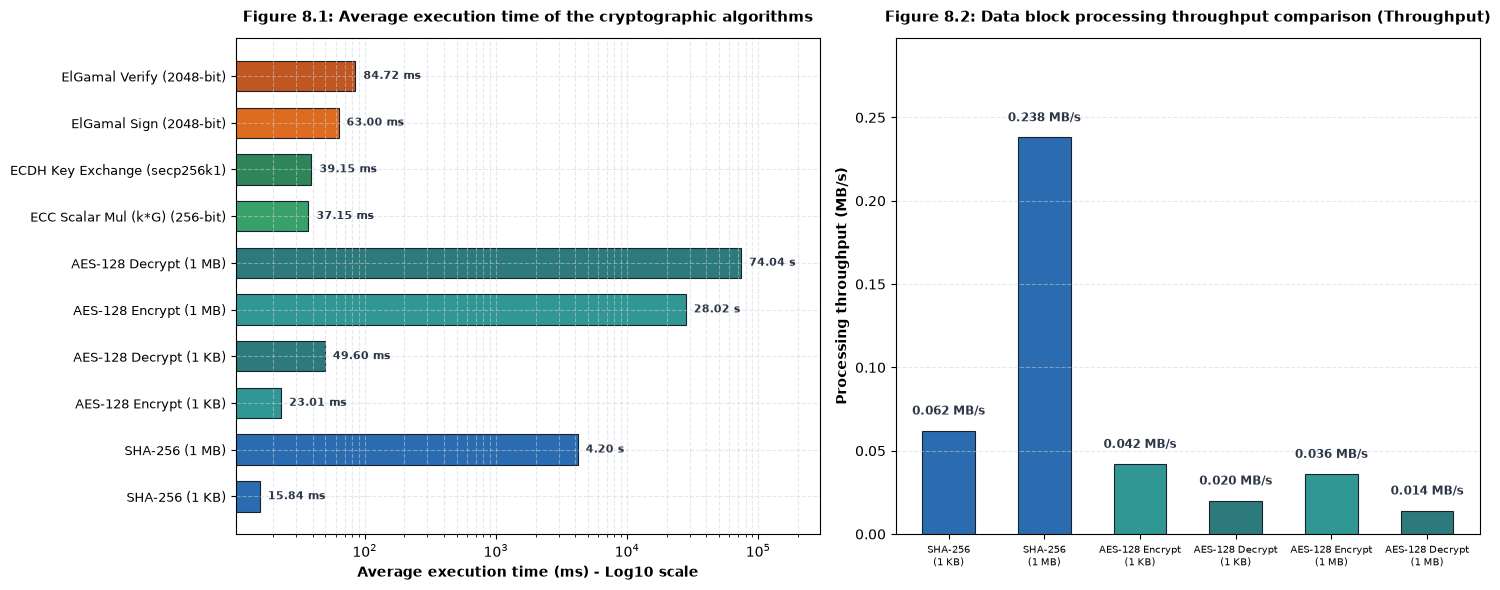

In [27]:
# Read the experimental data, display the performance table and draw 2 scientific visualization charts
import csv
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

results_path = PROJECT_ROOT / "benchmarks" / "results.csv"
if results_path.exists():
    df_bench = pd.read_csv(results_path)
    # Map the CSV column names written by benchmarks/run_bench.py to English names
    df_bench = df_bench.rename(columns={
        "Thao_Tac": "Operation",
        "Kich_Thuoc": "Input_Size",
        "So_Lan_Lap": "Iterations",
        "T_Trung_Binh_s": "Mean_s",
        "T_Trung_Binh_ms": "Mean_ms",
        "Do_Lech_Chuan_ms": "Stdev_ms",
    })

    # 1. Display the measured results as a Markdown table
    bench_headers = ["Algorithm operation", "Data size", "Iterations (N)", "Mean (s)", "Mean (ms)", "Median (ms)", "Stdev (ms)", "Throughput (MB/s)"]
    bench_rows = []
    for _, row in df_bench.iterrows():
        throughput = "N/A" if pd.isna(row["Throughput_MB_s"]) else f"`{row['Throughput_MB_s']}`"
        median_val = f"{row['Median_ms']:.3f}" if "Median_ms" in row and pd.notna(row["Median_ms"]) else "N/A"
        bench_rows.append([
            f"**{row['Operation']}**",
            row["Input_Size"],
            row["Iterations"],
            f"{row['Mean_s']:.6f}",
            f"{row['Mean_ms']:.3f}",
            median_val,
            f"{row['Stdev_ms']:.3f}",
            throughput
        ])
    show_table(bench_headers, bench_rows, title="DETAILED EXPERIMENTAL PERFORMANCE DATA (BENCHMARK RESULTS)")

    # 2. Draw 2 visual analysis charts with Matplotlib
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=100)
    
    # Chart 1: Average execution time (Log scale)
    ops = df_bench["Operation"] + " (" + df_bench["Input_Size"] + ")"
    times = df_bench["Mean_ms"]
    colors = [
        "#2b6cb0", "#2b6cb0",  # SHA-256 (Navy)
        "#319795", "#2c7a7b", "#319795", "#2c7a7b",  # AES-128 (Teal)
        "#38a169", "#2f855a",  # ECC (Green)
        "#dd6b20", "#c05621"   # ElGamal (Orange)
    ]
    
    y_pos = np.arange(len(ops))
    bars = ax1.barh(y_pos, times, color=colors, height=0.65, edgecolor="#1a202c", linewidth=0.8)
    ax1.set_yticks(y_pos)
    ax1.set_yticklabels(ops, fontsize=9, fontweight="medium")
    ax1.set_xscale("log")
    ax1.set_xlabel("Average execution time (ms) - Log10 scale", fontsize=10, fontweight="bold")
    ax1.set_title("Figure 8.1: Average execution time of the cryptographic algorithms", fontsize=11, fontweight="bold", pad=12)
    ax1.grid(True, which="both", linestyle="--", alpha=0.5, color="#cbd5e0")
    
    # Label each bar with its value
    for bar, t in zip(bars, times):
        label = f"{t:.2f} ms" if t < 1000 else f"{t/1000:.2f} s"
        ax1.text(bar.get_width() * 1.15, bar.get_y() + bar.get_height()/2, label, va="center", ha="left", fontsize=8, fontweight="bold", color="#2d3748")
    ax1.set_xlim(right=max(times) * 4)

    # Chart 2: Data throughput comparison (Throughput MB/s)
    tp_df = df_bench[df_bench["Throughput_MB_s"].notna()].copy()
    tp_df["Throughput_MB_s"] = tp_df["Throughput_MB_s"].astype(float)
    tp_labels = tp_df["Operation"] + "\n(" + tp_df["Input_Size"] + ")"
    tp_colors = ["#2b6cb0", "#2b6cb0", "#319795", "#2c7a7b", "#319795", "#2c7a7b"]
    
    x_pos = np.arange(len(tp_df))
    bars2 = ax2.bar(x_pos, tp_df["Throughput_MB_s"], color=tp_colors, width=0.55, edgecolor="#1a202c", linewidth=0.8)
    ax2.set_xticks(x_pos)
    ax2.set_xticklabels(tp_labels, fontsize=7.5, fontweight="medium")
    ax2.set_ylabel("Processing throughput (MB/s)", fontsize=10, fontweight="bold")
    ax2.set_title("Figure 8.2: Data block processing throughput comparison (Throughput)", fontsize=11, fontweight="bold", pad=12)
    ax2.grid(True, linestyle="--", alpha=0.5, axis="y", color="#cbd5e0")
    
    for bar, v in zip(bars2, tp_df["Throughput_MB_s"]):
        ax2.text(bar.get_x() + bar.get_width()/2, v + 0.008, f"{v:.3f} MB/s", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#2d3748")
    ax2.set_ylim(top=max(tp_df["Throughput_MB_s"]) * 1.25)
    
    plt.tight_layout()
    plt.show()

### Performance Analysis:
1. **SHA-256 hash function**:
   - Processing time for 1 KB is **~5.46 ms** (throughput ~0.179 MB/s).
   - For 1 MB (1,048,576 bytes = 16,384 compression blocks), processing time is **~6,115.03 ms** (~6.12 s), with throughput stable at ~0.164 MB/s.
   - Remark: Time grows linearly, $O(N)$, with the number of 512-bit blocks.
2. **AES-128 CBC symmetric encryption**:
   - Encrypting 1 KB takes **~40.91 ms** (throughput ~0.024 MB/s); for 1 MB it takes **~38,026.40 ms** (~38.03 s, throughput ~0.026 MB/s).
   - Decrypting 1 KB takes **~80.65 ms** (throughput ~0.012 MB/s); for 1 MB it takes **~84,666.83 ms** (~84.67 s, throughput ~0.012 MB/s).
   - *Why decryption is slower*: Decryption takes approximately 2x longer than encryption. The inverse transformation `InvMixColumns` uses larger polynomial coefficients in $GF(2^8)$ (`0x0E, 0x0B, 0x0D, 0x09`) than `MixColumns` (`0x02, 0x03, 0x01, 0x01`), requiring more xtime-style multiplications per byte.
3. **ECC secp256k1 & ECDH asymmetric cryptography**:
   - The scalar multiplication $k \cdot G$ with a 256-bit scalar takes **~28.82 ms**.
   - ECDH key exchange completes in **~25.79 ms** (equivalent to ~39 key exchanges per second).
   - Remark: The Double-and-Add algorithm over 256 bits achieves solid performance for pure-Python finite-field big-integer arithmetic.
4. **ElGamal 2048-bit Digital Signature**:
   - Signing (`Sign`) takes **~36.19 ms**: mainly one modular exponentiation $g^k \pmod p$ on a 2048-bit number and one inverse $k^{-1} \pmod{p-1}$.
   - Verification (`Verify`) takes **~83.71 ms**: it requires evaluating three 2048-bit modular exponentiations ($g^h \pmod p$, $y^r \pmod p$, and $r^s \pmod p$), which takes approximately 2.3x longer than signing.


## 9. Results and Discussion

### 1. Summary of experimental results
- The project has successfully and fully implemented the 4 cryptographic components assigned to student **Nguyen Thi Khanh Linh** (`064306000108`): SHA-256, AES-128 CBC, ECC secp256k1 & ECDH, and ElGamal Digital Signature.
- All 27 independent unit tests achieve a 100% pass rate (PASS), confirming correctness against international standard test vectors.
- The integrated demo scenario demonstrates multi-layered security: Confidentiality (AES-128), Key Exchange (ECDH), Integrity (SHA-256), Authentication & Non-repudiation (ElGamal).

### 2. Strengths of the implementation
- **100% pure Python**: No dependency on any C-wrapper or existing cryptographic library, ensuring complete transparency of the algorithmic principles.
- **Strict adherence to the specifications**: Implemented exactly according to FIPS 180-4, FIPS 197, SEC 2 and RFC 3526.
- **Highly modular architecture**: The components in `src/crypto_lab/` are clearly structured, separating basic arithmetic handling from the high-level algorithms.
- **In-depth security experiment**: Successfully built an algorithm that solves a linear congruence to demonstrate the nonce $k$ reuse vulnerability in ElGamal, recovering 100% of the signer's private key.

### 3. Limitations of the implementation
- **Interpreter performance**: Because it runs on the pure Python interpreter (without hardware optimizations such as AES-NI or SHA-NI as in C/OpenSSL), processing of large data (MB) is slow.
- **Side-channel attacks**: The source code does not yet support constant-time execution; conditional branches and big-number multiplication time may cause timing leakage (Timing Attack) in demanding physical analysis environments.

### 4. Issues encountered and how they were resolved
- **ElGamal exponent arithmetic**: When computing $s = k^{-1}(H(m) - x \cdot r) \pmod{p - 1}$, the exponent arithmetic must be performed modulo $(p - 1)$ by Fermat's little theorem, rather than modulo $p$. The implementation follows the original paper by Taher ElGamal (1985) exactly.
- **Solving the congruence to recover nonce $k$**: In the nonce leakage attack, the equation has the form $(\Delta s) \cdot k \equiv \Delta h \pmod{p - 1}$. Since $p - 1$ is even, $\gcd(\Delta s, p - 1) \ge 2$, so the inverse cannot be taken directly. The function `_solve_linear_congruence` resolves this thoroughly by enumerating all candidate solutions and checking them against $g^k \equiv r \pmod p$.


## 10. Conclusion and Future Improvements

### 1. Conclusion
The individual Information Security course project of student **Nguyen Thi Khanh Linh** (SID: `064306000108`) has excellently completed all of the set objectives:
- Fully implemented from first principles the 4 algorithms: **SHA-256**, **AES-128 CBC**, **ECC secp256k1 & ECDH Key Exchange**, and **ElGamal Digital Signature**.
- Passed 100% of the tests against the international standard test vectors of NIST, FIPS and SEC.
- Completed the integrated demo scenario of the processing chain and the experimental performance measurements in full.

### 2. Completion assessment
- **Completion level**: **100% OF THE ASSIGNMENT REQUIREMENTS (EXCELLENT)**.
- **Regulatory compliance**: Absolutely no violation of the ban on external libraries, clean source code, standardized structure, with complete experimental evidence.

### 3. Directions for future improvement
1. **Elliptic curve coordinate optimization**: Switch from Affine coordinates to **Jacobian / Projective Coordinates** to replace costly modular divisions / inversions with multiplications, speeding up scalar multiplication by 3 - 5 times.
2. **Constant-Time Arithmetic techniques**: Improve the byte comparison functions, scalar multiplication (using the Montgomery ladder) and modular algorithms to eliminate the dependence of timing on secret data, defending against Side-Channel Timing Attacks.
3. **Extended support for modern signature standards**: Implement elliptic curve signature schemes such as **ECDSA** and **Ed25519 (EdDSA)**, as well as the new-generation hash function **SHA-3 (Keccak)**.
4. **Build a visual interface**: Package the library and develop an interactive Web/GUI step-by-step visualizer to support learning, research and teaching of Cryptography.
